# Comprensión del negocio y Análisis Exploratorio de Datos (EDA)

**Proyecto final Machine Learning · Predicción de pago a tiempo de créditos**
Autor: Alejandro Botero · Docente: Juan Sebastián Parra Sánchez · Universidad Católica Luis Amigó

**Contenido**
1. Comprensión del negocio
2. Exploración inicial de datos (descripción, caracterización, nulos, variables irrelevantes, tipos)
3. Exploración y descripción (EDA): univariable, bivariable y multivariable
4. Atributos derivados
5. Reglas de validación de datos
6. Transformaciones propuestas
7. Conclusiones y siguientes pasos

## 1. Comprensión del negocio

**Contexto.** Una entidad que otorga créditos de consumo necesita decidir, en el momento de la solicitud, si aprueba o no un crédito. Cada registro de la base es un crédito otorgado entre noviembre de 2024 y abril de 2026, con información del cliente (edad, tipo laboral, salario), de las condiciones del crédito (capital, plazo, cuota) y de su comportamiento en la central de riesgo **Datacrédito** (puntaje, créditos vigentes, consultas, saldos, ingresos reportados).

**Pregunta de negocio.** *¿Va a pagar este cliente su crédito a tiempo?*

**Variable objetivo.** `Pago_atiempo` → 1 = pagó a tiempo, 0 = no pagó a tiempo. Se trata de un problema de **clasificación binaria supervisada**.

**¿Qué error es más costoso?**
- *Falso positivo para "paga"* (el modelo dice que paga y el cliente no paga): la entidad pierde capital → **es el error más caro**.
- *Falso negativo para "paga"* (el modelo rechaza a un buen cliente): se pierde el ingreso por intereses de ese cliente.

Por eso la clase de interés para el negocio es **`Pago_atiempo = 0`** y el modelo debe ser bueno detectándola (recall de la clase 0), no solo tener una exactitud alta.

### Diccionario de datos

No se entregó un diccionario oficial; la siguiente descripción es una **interpretación** a partir de los nombres y los valores observados.

| Variable | Descripción (interpretada) |
|---|---|
| `tipo_credito` | Código de la línea de crédito (4, 6, 7, 9, 10, 68) |
| `fecha_prestamo` | Fecha y hora de desembolso del crédito |
| `capital_prestado` | Monto prestado (COP) |
| `plazo_meses` | Plazo pactado en meses |
| `edad_cliente` | Edad del cliente en años |
| `tipo_laboral` | Empleado o Independiente |
| `salario_cliente` | Salario/ingreso mensual declarado por el cliente (COP) |
| `total_otros_prestamos` | Total de otras obligaciones declaradas (COP) |
| `cuota_pactada` | Valor de la cuota mensual del crédito (COP) |
| `puntaje` | Puntaje interno de la entidad (ver sección 2.5: **fuga de información**) |
| `puntaje_datacredito` | Puntaje de riesgo en Datacrédito (escala 150 – 950) |
| `cant_creditosvigentes` | Número de créditos vigentes en el sistema |
| `huella_consulta` | Número de consultas recientes a la central de riesgo |
| `saldo_mora` | Saldo en mora reportado en la central (COP) |
| `saldo_total` | Saldo total de obligaciones reportadas (COP) |
| `saldo_principal` | Saldo de capital de obligaciones reportadas (COP) |
| `saldo_mora_codeudor` | Saldo en mora como codeudor (COP) |
| `creditos_sectorFinanciero` | Créditos con el sector financiero |
| `creditos_sectorCooperativo` | Créditos con el sector cooperativo |
| `creditos_sectorReal` | Créditos con el sector real (comercio, telefonía, etc.) |
| `promedio_ingresos_datacredito` | Ingreso promedio estimado por Datacrédito (COP) |
| `tendencia_ingresos` | Tendencia de los ingresos: Creciente, Estable o Decreciente |
| `Pago_atiempo` | **Objetivo**: 1 = pagó a tiempo, 0 = no |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90

OBJETIVO = "Pago_atiempo"
PALETA = {0: "#C0392B", 1: "#2E86C1"}
ETIQUETAS = {0: "No pagó a tiempo", 1: "Pagó a tiempo"}


def con_sin_informacion(serie):
    # Muestra los nulos como la categoría "Sin información" (solo para tablas y gráficos).
    return serie.astype(object).where(serie.notna(), "Sin información").astype(str)

**Carga de datos.** Se reutiliza la función `cargar_datos()` del notebook `Cargar_datos.ipynb`, para que todo el pipeline lea la base de la misma forma y con las mismas validaciones de esquema.

In [2]:
MOSTRAR_RESUMEN = False
%run -i ./Cargar_datos.ipynb

df_crudo = df.copy()   # copia intacta de la base original, para comparar y validar
print(f"Base cargada: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Base cargada: 10,763 filas x 23 columnas


## 2. Exploración inicial de datos

### 2.1 Descripción general

In [3]:
df.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,"1,852,560.00",12,32,Empleado,3500000,1000000,128650,95.23,795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1
1,4,2025-01-09 11:18:48,"3,181,080.00",6,34,Empleado,5000000,2000000,441817,95.23,796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1
2,9,2024-12-26 18:52:57,"670,200.00",5,34,Independiente,5000000,2000000,108632,95.23,727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,"506,806.80",2,25,Independiente,3000000,900000,199684,95.23,864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,"999,780.00",10,26,Empleado,2000000,600000,92509,95.23,771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  str           
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvigentes     

In [5]:
print(f"Registros duplicados (todas las columnas): {df.duplicated().sum()}")
print(f"Fechas de préstamo únicas: {df['fecha_prestamo'].nunique():,} de {len(df):,}")

Registros duplicados (todas las columnas): 0
Fechas de préstamo únicas: 10,758 de 10,763


**Interpretación**
- La base tiene **10.763 créditos y 23 variables**, sin registros duplicados.
- Las fechas son prácticamente únicas por registro (fecha y hora exacta del desembolso), así que cada fila corresponde a un crédito distinto.
- Pandas infiere 12 columnas enteras, 8 decimales, 2 de texto y 1 fecha, pero el tipo que asigna pandas **no siempre es el tipo real** de la variable: por ejemplo, `tipo_credito` es un número que en realidad representa una categoría. Eso se caracteriza a continuación.

### 2.2 Caracterización de las variables

Se clasifica cada variable según su naturaleza:
- **Numérica continua / discreta**: valores medibles (montos) o conteos.
- **Categórica nominal**: categorías sin orden. **Ordinal**: categorías con orden.
- **Dicotómica**: solo dos valores. **Politómica**: más de dos.

In [6]:
caracterizacion = {
    "tipo_credito":                  ("Categórica", "Nominal", "Politómica"),
    "fecha_prestamo":                ("Fecha", "-", "-"),
    "capital_prestado":              ("Numérica", "Continua", "-"),
    "plazo_meses":                   ("Numérica", "Discreta", "-"),
    "edad_cliente":                  ("Numérica", "Discreta", "-"),
    "tipo_laboral":                  ("Categórica", "Nominal", "Dicotómica"),
    "salario_cliente":               ("Numérica", "Continua", "-"),
    "total_otros_prestamos":         ("Numérica", "Continua", "-"),
    "cuota_pactada":                 ("Numérica", "Continua", "-"),
    "puntaje":                       ("Numérica", "Continua", "-"),
    "puntaje_datacredito":           ("Numérica", "Discreta", "-"),
    "cant_creditosvigentes":         ("Numérica", "Discreta", "-"),
    "huella_consulta":               ("Numérica", "Discreta", "-"),
    "saldo_mora":                    ("Numérica", "Continua", "-"),
    "saldo_total":                   ("Numérica", "Continua", "-"),
    "saldo_principal":               ("Numérica", "Continua", "-"),
    "saldo_mora_codeudor":           ("Numérica", "Continua", "-"),
    "creditos_sectorFinanciero":     ("Numérica", "Discreta", "-"),
    "creditos_sectorCooperativo":    ("Numérica", "Discreta", "-"),
    "creditos_sectorReal":           ("Numérica", "Discreta", "-"),
    "promedio_ingresos_datacredito": ("Numérica", "Continua", "-"),
    "tendencia_ingresos":            ("Categórica", "Ordinal", "Politómica"),
    "Pago_atiempo":                  ("Categórica", "Nominal", "Dicotómica (objetivo)"),
}

tabla_caract = pd.DataFrame(caracterizacion, index=["tipo", "subtipo", "n_categorias"]).T
tabla_caract["dtype_pandas"] = df.dtypes.astype(str)
tabla_caract["valores_unicos"] = df.nunique()
tabla_caract["nulos"] = df.isna().sum()
tabla_caract["%_nulos"] = (df.isna().mean() * 100).round(2)
tabla_caract["ejemplo"] = df.iloc[0].astype(str)
tabla_caract

,tipo,subtipo,n_categorias,dtype_pandas,valores_unicos,nulos,%_nulos,ejemplo
tipo_credito,Categórica,Nominal,Politómica,int64,6,0,0.00,4
fecha_prestamo,Fecha,-,-,datetime64[us],10758,0,0.00,2025-01-07 14:40:36
capital_prestado,Numérica,Continua,-,float64,7306,0,0.00,1852560.0
plazo_meses,Numérica,Discreta,-,int64,18,0,0.00,12
edad_cliente,Numérica,Discreta,-,int64,54,0,0.00,32
tipo_laboral,Categórica,Nominal,Dicotómica,str,2,0,0.00,Empleado
salario_cliente,Numérica,Continua,-,int64,1385,0,0.00,3500000
total_otros_prestamos,Numérica,Continua,-,int64,1538,0,0.00,1000000
cuota_pactada,Numérica,Continua,-,int64,9836,0,0.00,128650
puntaje,Numérica,Continua,-,float64,248,0,0.00,95.227787


In [7]:
tabla_caract.groupby(["tipo", "subtipo"]).size().rename("cantidad").to_frame()

cantidad
tipo       subtipo           
Categórica Nominal          3
           Ordinal          1
Fecha      -                1
Numérica   Continua        10
           Discreta         8

**Interpretación**
- **18 variables numéricas**: 10 continuas (montos en pesos y el puntaje interno) y 8 discretas (conteos, plazo, edad y puntaje Datacrédito).
- **4 categóricas**: `tipo_credito` (nominal politómica, aunque viene codificada como número), `tipo_laboral` (nominal dicotómica), `tendencia_ingresos` (**ordinal**: Decreciente < Estable < Creciente) y la objetivo `Pago_atiempo` (dicotómica).
- **1 fecha**: `fecha_prestamo`.
- `tendencia_ingresos` tiene **46 valores únicos** cuando solo debería tener 3: es la primera señal de datos sucios.

### 2.3 Revisión de nulos

In [8]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "%_nulos": (df.isna().mean() * 100).round(2),
}).query("nulos > 0").sort_values("nulos", ascending=False)
nulos

,nulos,%_nulos
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


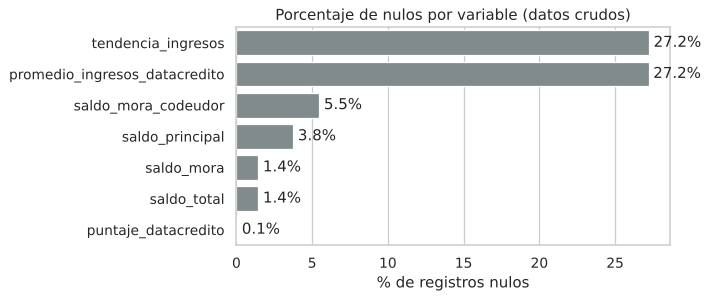

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=nulos["%_nulos"], y=nulos.index, color="#7F8C8D", ax=ax)
ax.set_title("Porcentaje de nulos por variable (datos crudos)")
ax.set_xlabel("% de registros nulos")
ax.set_ylabel("")
for i, v in enumerate(nulos["%_nulos"]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

¿Los nulos aparecen juntos? Si dos variables tienen casi el mismo número de nulos, conviene revisar si faltan en los mismos registros (eso indica una **causa común**).

In [10]:
print("promedio_ingresos_datacredito nulo vs tendencia_ingresos nulo")
display(pd.crosstab(df["promedio_ingresos_datacredito"].isna(), df["tendencia_ingresos"].isna(),
                    rownames=["promedio nulo"], colnames=["tendencia nulo"]))
print("saldo_mora nulo vs saldo_total nulo")
display(pd.crosstab(df["saldo_mora"].isna(), df["saldo_total"].isna(),
                    rownames=["saldo_mora nulo"], colnames=["saldo_total nulo"]))

promedio_ingresos_datacredito nulo vs tendencia_ingresos nulo


tendencia nulo,False,True
promedio nulo,,
False,7831,2
True,0,2930


saldo_mora nulo vs saldo_total nulo


saldo_total nulo,False,True
saldo_mora nulo,,
False,10607,0
True,0,156


**Interpretación**
- El mayor volumen de nulos está en `promedio_ingresos_datacredito` (27,2 %) y `tendencia_ingresos` (27,2 %), y **faltan en los mismos registros** (2.930 coinciden): son clientes para los que Datacrédito no tiene información de ingresos. Por lo tanto, el nulo **no es aleatorio**: es información en sí misma ("cliente sin información de ingresos en la central").
- `saldo_mora` y `saldo_total` tienen exactamente los mismos 156 nulos: la consulta de saldos no trajo información para esos clientes.
- `saldo_mora_codeudor` tiene 590 nulos (5,5 %) y `saldo_principal` 405 (3,8 %).
- `puntaje_datacredito` solo tiene 6 nulos visibles, pero en la siguiente sección se muestra que hay muchos más **nulos disfrazados**.

### 2.4 Unificar la representación de los valores nulos

Un valor faltante no siempre aparece como `NaN`. Puede venir como:
1. **Texto** que significa "vacío": `""`, `"NA"`, `"null"`, `"-"`...
2. **Valores imposibles o códigos** que en realidad indican ausencia de dato: edad de 122 años, salario 0, puntaje Datacrédito 0...
3. **Valores de otro tipo** mezclados en la columna: números dentro de una variable categórica.

El objetivo es que **todo dato faltante quede representado de una sola forma: `np.nan`**.

In [11]:
# 1) Textos que representan nulos en las columnas de texto
TEXTOS_NULOS = ["", " ", "NA", "N/A", "na", "null", "NULL", "None", "nan", "NaN", "-", "?"]
for col in ["tipo_laboral", "tendencia_ingresos"]:
    encontrados = df[col].astype(str).str.strip().isin(TEXTOS_NULOS) & df[col].notna()
    print(f"{col}: {encontrados.sum()} valores de texto que representan nulo")

tipo_laboral: 0 valores de texto que representan nulo
tendencia_ingresos: 0 valores de texto que representan nulo


In [12]:
# 2) Valores de otro tipo mezclados en tendencia_ingresos
df["tendencia_ingresos"].value_counts(dropna=False).head(10)

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
Name: count, dtype: int64

In [13]:
CATEGORIAS_TENDENCIA = ["Decreciente", "Estable", "Creciente"]
invalidos = df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(CATEGORIAS_TENDENCIA)
print(f"Registros con un valor no válido en tendencia_ingresos: {invalidos.sum()}")
print("Ejemplos:", df.loc[invalidos, "tendencia_ingresos"].unique()[:12])

Registros con un valor no válido en tendencia_ingresos: 58
Ejemplos: <StringArray>
[   '8315',       '0',  '158042',    '3978',    '9147',  '168750',  '-28589',
 '1000000', '-566272',   '24702',   '31837',  '122727']
Length: 12, dtype: str


In [14]:
# 3) Valores imposibles o códigos en variables numéricas
revision = pd.DataFrame({
    "edad > 100 años": [(df["edad_cliente"] > 100).sum()],
    "salario < 100.000": [(df["salario_cliente"] < 100_000).sum()],
    "salario > 100 millones": [(df["salario_cliente"] > 100_000_000).sum()],
    "otros préstamos > 1.000 millones": [(df["total_otros_prestamos"] > 1_000_000_000).sum()],
    "puntaje Datacrédito fuera de 150-950": [((df["puntaje_datacredito"] < 150) | (df["puntaje_datacredito"] > 950)).sum()],
    "plazo > 60 meses": [(df["plazo_meses"] > 60).sum()],
}, index=["registros"]).T
revision

,registros
edad > 100 años,150
salario < 100.000,31
salario > 100 millones,74
otros préstamos > 1.000 millones,13
puntaje Datacrédito fuera de 150-950,153
plazo > 60 meses,1


In [15]:
print("Edades mayores a 100:", df.loc[df["edad_cliente"] > 100, "edad_cliente"].value_counts().to_dict())
print("Puntajes Datacrédito < 150:", df.loc[df["puntaje_datacredito"] < 150, "puntaje_datacredito"].value_counts().to_dict())
print("Salarios más altos:", sorted(df["salario_cliente"].nlargest(5).tolist()))

Edades mayores a 100: {122: 144, 121: 4, 123: 2}
Puntajes Datacrédito < 150: {0.0: 145, 7.0: 1, -7.0: 1}
Salarios más altos: [8252584000, 12450806583, 13258352050, 16991100000, 22000000000]


**Decisiones**

| Problema | Hallazgo | Acción |
|---|---|---|
| Textos nulos | No hay textos tipo "NA", "null", etc. | Ninguna |
| `tendencia_ingresos` | 58 registros con números en lugar de una categoría | → `NaN` |
| `edad_cliente` | 150 clientes con 121 – 123 años (valor imposible; probablemente un código por defecto) | → `NaN` |
| `salario_cliente` | 24 en 0, 7 por debajo de 100.000 y 74 por encima de 100 millones (máximo 22.000 millones): errores de digitación | → `NaN` |
| `total_otros_prestamos` | 13 registros por encima de 1.000 millones | → `NaN` |
| `puntaje_datacredito` | 145 en 0 (sin puntaje), valores como -7 y 7, y 6 por encima de 950: fuera de la escala 150 – 950 | → `NaN` |
| `plazo_meses` | 1 crédito a 90 meses, muy por fuera del resto (máx. siguiente: 48) | → `NaN` |

> Los umbrales de salario y otros préstamos son **supuestos de negocio** razonables para crédito de consumo y deberían validarse con el área de riesgo.

In [16]:
def a_nulo(datos, condicion, columna, descripcion, registro):
    # Reemplaza por NaN los valores que cumplen la condición y guarda cuántos fueron.
    cantidad = int(condicion.sum())
    datos.loc[condicion, columna] = np.nan
    registro.append({"variable": columna, "regla": descripcion, "valores_a_nulo": cantidad})


cambios = []
a_nulo(df, df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(CATEGORIAS_TENDENCIA),
       "tendencia_ingresos", "valor fuera de {Decreciente, Estable, Creciente}", cambios)
a_nulo(df, df["edad_cliente"] > 100, "edad_cliente", "edad > 100", cambios)
a_nulo(df, (df["salario_cliente"] < 100_000) | (df["salario_cliente"] > 100_000_000),
       "salario_cliente", "salario < 100 mil o > 100 millones", cambios)
a_nulo(df, df["total_otros_prestamos"] > 1_000_000_000, "total_otros_prestamos", "> 1.000 millones", cambios)
a_nulo(df, (df["puntaje_datacredito"] < 150) | (df["puntaje_datacredito"] > 950),
       "puntaje_datacredito", "fuera de la escala 150 - 950", cambios)
a_nulo(df, df["plazo_meses"] > 60, "plazo_meses", "plazo > 60 meses", cambios)

pd.DataFrame(cambios)

,variable,regla,valores_a_nulo
0,tendencia_ingresos,"valor fuera de {Decreciente, Estable, Creciente}",58
1,edad_cliente,edad > 100,150
2,salario_cliente,salario < 100 mil o > 100 millones,105
3,total_otros_prestamos,> 1.000 millones,13
4,puntaje_datacredito,fuera de la escala 150 - 950,153
5,plazo_meses,plazo > 60 meses,1


In [17]:
comparacion_nulos = pd.DataFrame({
    "nulos_antes": df_crudo.isna().sum(),
    "nulos_despues": df.isna().sum(),
})
comparacion_nulos["%_despues"] = (comparacion_nulos["nulos_despues"] / len(df) * 100).round(2)
comparacion_nulos.query("nulos_despues > 0").sort_values("nulos_despues", ascending=False)

,nulos_antes,nulos_despues,%_despues
tendencia_ingresos,2932,2990,27.78
promedio_ingresos_datacredito,2930,2930,27.22
saldo_mora_codeudor,590,590,5.48
saldo_principal,405,405,3.76
puntaje_datacredito,6,159,1.48
saldo_total,156,156,1.45
saldo_mora,156,156,1.45
edad_cliente,0,150,1.39
salario_cliente,0,105,0.98
total_otros_prestamos,0,13,0.12


**Interpretación.** Ahora todos los datos faltantes están representados como `NaN`. Los nulos "reales" pasaron de estar escondidos a ser visibles: por ejemplo, `puntaje_datacredito` pasó de 6 a 159 nulos y `edad_cliente` de 0 a 150. Ningún registro se eliminó; la **imputación** de estos nulos se hará en la Fase 2 dentro del pipeline (`SimpleImputer`), para que se aprenda solo con los datos de entrenamiento y no haya fuga de información.

### 2.5 Eliminación de variables irrelevantes

#### `puntaje`: fuga de información (*data leakage*)

Al revisar las correlaciones con la variable objetivo, `puntaje` tiene una relación sospechosamente perfecta. Se investiga:

In [18]:
print(f"Correlación de Pearson puntaje vs {OBJETIVO}: {df['puntaje'].corr(df[OBJETIVO]):.3f}")
print(f"Correlación de la siguiente variable más fuerte: "
      f"{df.drop(columns=['puntaje']).select_dtypes('number').corr()[OBJETIVO].drop(OBJETIVO).abs().max():.3f}")

display(pd.crosstab(np.where(df["puntaje"] < 60, "puntaje < 60", "puntaje >= 60"), df[OBJETIVO],
                    rownames=["puntaje"], colnames=[OBJETIVO]))

Correlación de Pearson puntaje vs Pago_atiempo: 0.923
Correlación de la siguiente variable más fuerte: 0.121


Pago_atiempo,0,1
puntaje,,
puntaje < 60,492,0
puntaje >= 60,19,10252


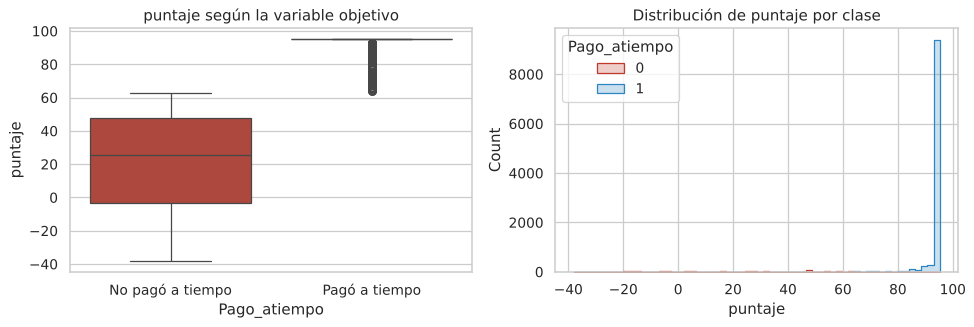

Registros con el puntaje máximo (95.2278): 9,407 -> todos con Pago_atiempo = [1]


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x=OBJETIVO, y="puntaje", hue=OBJETIVO, palette=PALETA, legend=False, ax=axes[0])
axes[0].set_xticks([0, 1], [ETIQUETAS[0], ETIQUETAS[1]])
axes[0].set_title("puntaje según la variable objetivo")
sns.histplot(data=df, x="puntaje", hue=OBJETIVO, palette=PALETA, bins=60, ax=axes[1], element="step")
axes[1].set_title("Distribución de puntaje por clase")
plt.tight_layout()
plt.show()

print(f"Registros con el puntaje máximo ({df['puntaje'].max():.4f}): {(df['puntaje'] == df['puntaje'].max()).sum():,} "
      f"-> todos con {OBJETIVO} = {df.loc[df['puntaje'] == df['puntaje'].max(), OBJETIVO].unique()}")

**Interpretación.** Con una sola regla (`puntaje < 60` → no paga) se clasifican correctamente **10.744 de 10.763 créditos (99,8 %)**: los 492 clientes con puntaje menor a 60 son todos morosos, y los 9.407 con el puntaje máximo pagaron todos. La siguiente variable con mayor correlación apenas llega a 0,12.

Eso no es una variable predictiva, es una **fuga de información**: casi con certeza el `puntaje` se calcula o se actualiza **después** de conocer el comportamiento de pago del cliente. En el momento real de aprobar el crédito ese valor no existiría así, de modo que un modelo entrenado con él tendría métricas casi perfectas en el laboratorio y fallaría en producción.

**Decisión: se elimina `puntaje`.**

#### `saldo_mora_codeudor`: variable casi constante

In [20]:
df["saldo_mora_codeudor"].value_counts(dropna=False)

saldo_mora_codeudor
0.00        10170
NaN           590
30.00           1
470.00          1
2,145.00        1
Name: count, dtype: int64

**Interpretación.** De 10.763 registros, 10.170 valen 0, 590 son nulos y solo **3** tienen un valor distinto de cero. Una variable que es prácticamente constante no aporta información para diferenciar a los clientes. **Decisión: se elimina.**

#### `fecha_prestamo`
No se usará directamente como variable de entrada del modelo (una fecha exacta no se repite en el futuro), pero **se conserva** porque:
- de ella se derivan atributos útiles (mes, día de la semana), y
- será necesaria en la etapa de **monitoreo** para analizar el *data drift* en el tiempo.

In [21]:
VARIABLES_ELIMINADAS = ["puntaje", "saldo_mora_codeudor"]
df = df.drop(columns=VARIABLES_ELIMINADAS)
print(f"Variables eliminadas: {VARIABLES_ELIMINADAS}")
print(f"Dimensión actual: {df.shape}")

Variables eliminadas: ['puntaje', 'saldo_mora_codeudor']
Dimensión actual: (10763, 21)


### 2.6 Conversión de los datos a su tipo correcto

In [22]:
tipos_antes = df.dtypes.astype(str)

# Categórica nominal codificada como número -> categoría
df["tipo_credito"] = df["tipo_credito"].astype(str).astype("category")

# Categórica nominal dicotómica
df["tipo_laboral"] = df["tipo_laboral"].astype("category")

# Categórica ORDINAL: se define el orden explícitamente
df["tendencia_ingresos"] = pd.Categorical(df["tendencia_ingresos"], categories=CATEGORIAS_TENDENCIA, ordered=True)

# Fecha
df["fecha_prestamo"] = pd.to_datetime(df["fecha_prestamo"])

# Objetivo: se deja como entero 0/1 (formato que esperan los modelos de scikit-learn)
df[OBJETIVO] = df[OBJETIVO].astype(int)

# Variables numéricas: todas a float (las que recibieron NaN ya no pueden ser enteras)
NUMERICAS = [c for c, (t, *_r) in caracterizacion.items() if t == "Numérica" and c in df.columns]
df[NUMERICAS] = df[NUMERICAS].astype(float)

CATEGORICAS = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]

pd.DataFrame({"tipo_antes": tipos_antes, "tipo_despues": df.dtypes.astype(str)})

,tipo_antes,tipo_despues
tipo_credito,int64,category
fecha_prestamo,datetime64[us],datetime64[us]
capital_prestado,float64,float64
plazo_meses,float64,float64
edad_cliente,float64,float64
tipo_laboral,str,category
salario_cliente,float64,float64
total_otros_prestamos,float64,float64
cuota_pactada,int64,float64
puntaje_datacredito,float64,float64


**Interpretación.** Cada columna tiene ahora un tipo uniforme y acorde a su naturaleza:
- `tipo_credito` deja de ser un número: si se dejara como entero, un modelo interpretaría que el tipo 68 es "mayor" que el tipo 4, lo cual no tiene sentido.
- `tendencia_ingresos` queda como categórica **ordenada** (Decreciente < Estable < Creciente), lo que permitirá usar un `OrdinalEncoder` en la Fase 2.
- Las 16 numéricas quedan como `float` y la objetivo como entero 0/1.

## 3. Exploración de datos y descripción (EDA)

### 3.1 Análisis univariable

#### Variable objetivo

,registros,%
No pagó a tiempo,511,4.75
Pagó a tiempo,10252,95.25


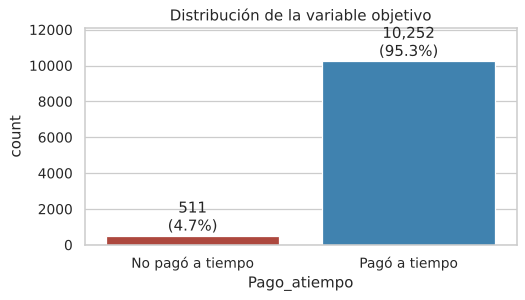

In [23]:
conteo_obj = df[OBJETIVO].value_counts().sort_index()
tabla_obj = pd.DataFrame({"registros": conteo_obj, "%": (conteo_obj / len(df) * 100).round(2)})
tabla_obj.index = [ETIQUETAS[i] for i in tabla_obj.index]
display(tabla_obj)

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(data=df, x=OBJETIVO, hue=OBJETIVO, palette=PALETA, legend=False, ax=ax)
ax.set_xticks([0, 1], [ETIQUETAS[0], ETIQUETAS[1]])
ax.set_title("Distribución de la variable objetivo")
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}\n({p.get_height() / len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_ylim(0, conteo_obj.max() * 1.18)
plt.tight_layout()
plt.show()

**Interpretación.** La variable objetivo está **muy desbalanceada**: 95,25 % pagó a tiempo y solo 4,75 % (511 créditos) no. Consecuencias para la Fase 2:
- Un modelo que diga "todos pagan" tendría 95 % de exactitud (*accuracy*) y sería inútil. **La exactitud no sirve como métrica principal**; se usarán *recall* y *precision* de la clase 0, F1, ROC-AUC y PR-AUC.
- La partición train/test debe ser **estratificada** para conservar la proporción 95/5.
- Habrá que compensar el desbalance (`class_weight="balanced"`, ajuste del umbral de decisión o técnicas de remuestreo).

#### Variables numéricas

Primero el `describe()` con los tipos ya corregidos, y luego una tabla más completa con medidas de tendencia central, dispersión y forma.

In [24]:
df[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,762.00",10.57,6.59,2.00,6.00,10.00,12.00,48.00
edad_cliente,"10,613.00",42.85,11.95,19.00,33.00,42.00,52.00,69.00
salario_cliente,"10,658.00","4,118,092.90","5,103,325.02","243,798.00","2,000,000.00","3,000,000.00","4,765,250.00","95,985,077.00"
total_otros_prestamos,"10,750.00","2,783,929.40","24,826,126.95",0.00,"500,000.00","1,000,000.00","2,000,000.00","934,303,642.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje_datacredito,"10,604.00",791.50,50.69,287.00,758.00,792.00,826.00,947.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00
saldo_mora,"10,607.00",7.75,225.96,0.00,0.00,0.00,0.00,"12,534.00"


In [25]:
def tipo_distribucion(serie):
    # Clasificación aproximada de la forma de la distribución a partir de asimetría y curtosis.
    s = serie.dropna()
    asimetria, curtosis = s.skew(), s.kurt()
    if (s == 0).mean() > 0.5:
        return "Concentrada en cero"
    if abs(asimetria) < 0.5:
        if curtosis < -0.5:
            return "Simétrica, platicúrtica (tiende a uniforme)"
        return "Aprox. gaussiana"
    if asimetria >= 0.5:
        if (s > 0).all() and abs(np.log(s).skew()) < 0.5:
            return "Log-normal (sesgo a la derecha)"
        return "Sesgada a la derecha"
    return "Sesgada a la izquierda"


def resumen_estadistico(datos, columnas):
    # Medidas de tendencia central, dispersión y forma para variables numéricas.
    filas = []
    for col in columnas:
        s = datos[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        atipicos = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
        filas.append({
            "variable": col, "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
            "min": s.min(), "max": s.max(), "rango": s.max() - s.min(),
            "Q1": q1, "Q3": q3, "IQR": iqr, "varianza": s.var(), "desv_std": s.std(),
            "asimetria": s.skew(), "curtosis": s.kurt(), "%_atipicos_IQR": atipicos,
            "distribucion": tipo_distribucion(s),
        })
    return pd.DataFrame(filas).set_index("variable")


resumen_num = resumen_estadistico(df, NUMERICAS)
resumen_num

,media,mediana,moda,min,max,rango,Q1,Q3,IQR,varianza,desv_std,asimetria,curtosis,%_atipicos_IQR,distribucion
variable,,,,,,,,,,,,,,,
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80","1,224,831.00","3,084,840.00","1,860,009.00","3,646,735,466,988.66","1,909,642.76",3.72,35.32,5.11,Log-normal (sesgo a la derecha)
plazo_meses,10.57,10.00,6.00,2.00,48.00,46.00,6.00,12.00,6.00,43.40,6.59,2.35,6.12,8.07,Log-normal (sesgo a la derecha)
edad_cliente,42.85,42.00,40.00,19.00,69.00,50.00,33.00,52.00,19.00,142.74,11.95,0.27,-0.86,0.00,"Simétrica, platicúrtica (tiende a uniforme)"
salario_cliente,"4,118,092.90","3,000,000.00","3,000,000.00","243,798.00","95,985,077.00","95,741,279.00","2,000,000.00","4,765,250.00","2,765,250.00","26,043,926,263,819.13","5,103,325.02",8.68,113.16,6.59,Sesgada a la derecha
total_otros_prestamos,"2,783,929.40","1,000,000.00","2,000,000.00",0.00,"934,303,642.00","934,303,642.00","500,000.00","2,000,000.00","1,500,000.00","616,336,579,475,531.12","24,826,126.95",26.11,768.05,5.36,Sesgada a la derecha
cuota_pactada,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","3,792,808.00","121,041.50","287,833.50","166,792.00","44,307,595,469.58","210,493.69",3.79,26.65,7.11,Log-normal (sesgo a la derecha)
puntaje_datacredito,791.50,792.00,783.00,287.00,947.00,660.00,758.00,826.00,68.00,"2,569.80",50.69,-0.71,5.24,0.41,Sesgada a la izquierda
cant_creditosvigentes,5.73,5.00,4.00,0.00,62.00,62.00,3.00,8.00,5.00,15.82,3.98,1.80,8.62,2.25,Sesgada a la derecha
huella_consulta,4.23,4.00,2.00,0.00,29.00,29.00,2.00,6.00,4.00,9.39,3.06,1.49,4.00,2.01,Sesgada a la derecha


**Interpretación**
- **Casi todas las variables monetarias** (capital, salario, cuota, otros préstamos, saldos, ingresos Datacrédito) tienen **asimetría positiva fuerte** (cola larga a la derecha): pocos clientes con montos muy altos y la mayoría con montos moderados. En todas ellas la **media es mayor que la mediana**, por eso la mediana describe mejor al "cliente típico" (por ejemplo, capital mediano ≈ 1,9 millones frente a una media ≈ 2,4 millones).
- `capital_prestado` y `cuota_pactada` se comportan como **log-normales**: al aplicarles logaritmo se vuelven aproximadamente simétricas.
- `saldo_mora` está **concentrada en cero**: solo 55 clientes tienen saldo en mora. Más útil que el monto será una bandera "tiene mora sí/no".
- `edad_cliente` es la única aproximadamente **simétrica** (asimetría 0,27), aunque más plana que una normal (curtosis negativa): hay clientes repartidos de forma bastante pareja entre 19 y 69 años, con mediana de 42.
- `puntaje_datacredito` tiene un leve sesgo a la izquierda: la mayoría tiene buen puntaje (mediana 792) y una cola de clientes con puntajes bajos.
- Las curtosis muy altas (por ejemplo, `total_otros_prestamos` o `saldo_mora`) confirman la presencia de **valores atípicos extremos**, que pesarán mucho en modelos sensibles a la escala (regresión logística, KNN). Se recomienda transformación logarítmica o escalado robusto.

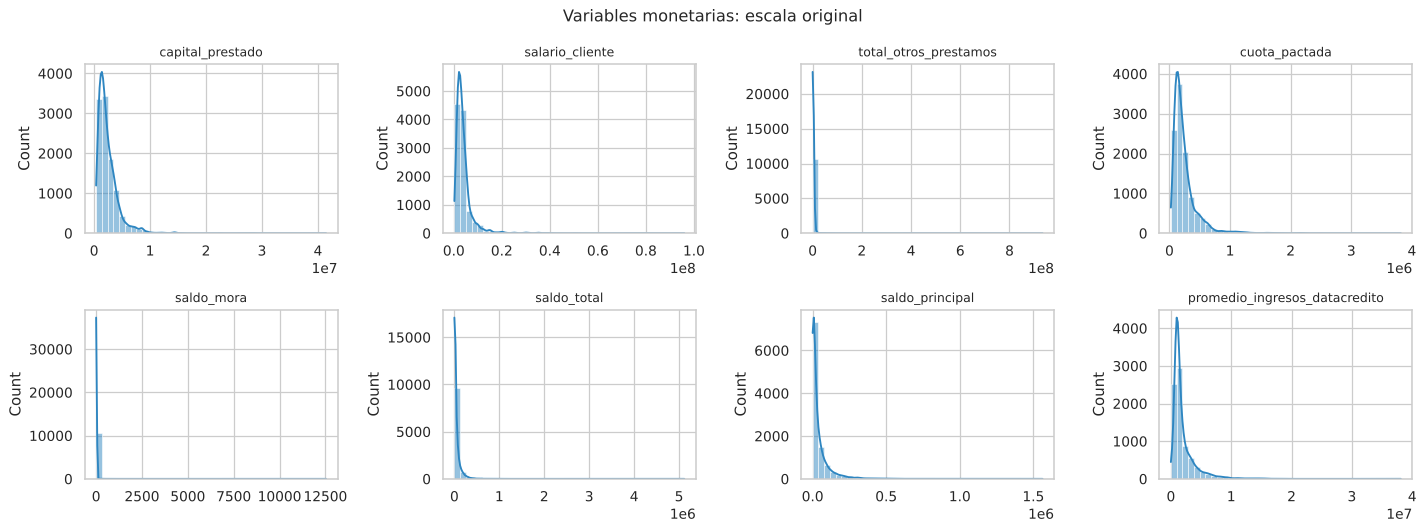

In [26]:
MONETARIAS = ["capital_prestado", "salario_cliente", "total_otros_prestamos", "cuota_pactada",
              "saldo_mora", "saldo_total", "saldo_principal", "promedio_ingresos_datacredito"]
CONTEOS = [c for c in NUMERICAS if c not in MONETARIAS]


def grilla_histogramas(datos, columnas, titulo, log=False, n_col=4):
    n_filas = int(np.ceil(len(columnas) / n_col))
    fig, axes = plt.subplots(n_filas, n_col, figsize=(4 * n_col, 3 * n_filas))
    for ax, col in zip(axes.flat, columnas):
        serie = np.log1p(datos[col].dropna()) if log else datos[col].dropna()
        sns.histplot(serie, bins=40, kde=True, color="#2E86C1", ax=ax)
        ax.set_title(f"log(1 + {col})" if log else col, fontsize=10)
        ax.set_xlabel("")
    for ax in list(axes.flat)[len(columnas):]:
        ax.set_visible(False)
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()


grilla_histogramas(df, MONETARIAS, "Variables monetarias: escala original")

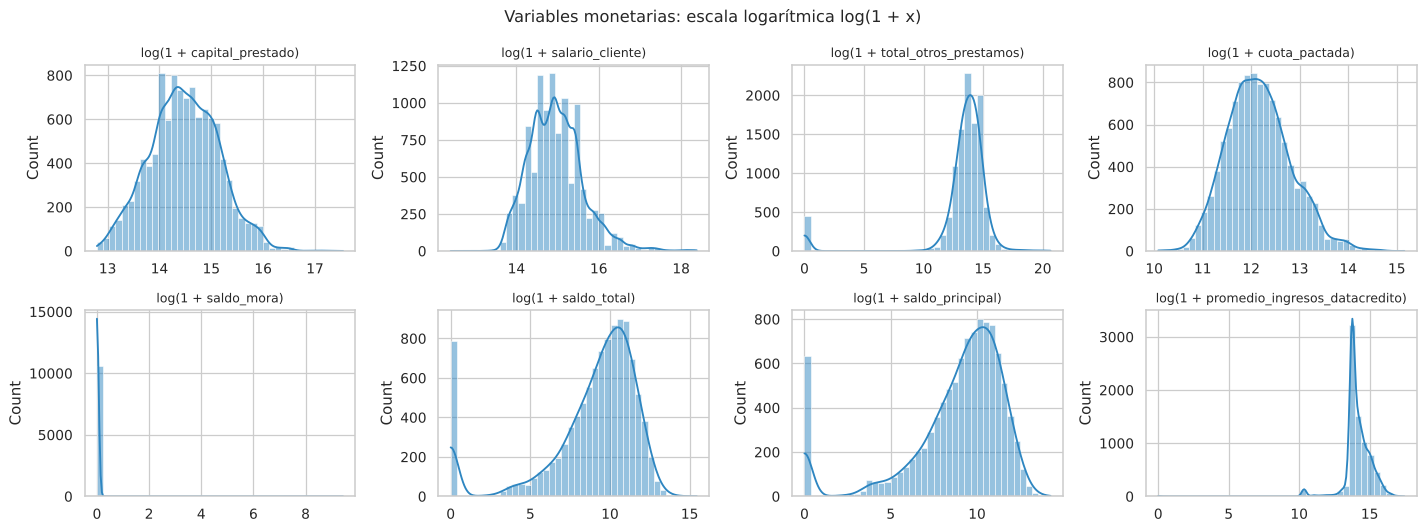

In [27]:
grilla_histogramas(df, MONETARIAS, "Variables monetarias: escala logarítmica log(1 + x)", log=True)

**Interpretación.** En escala original las variables monetarias se ven como una sola barra pegada a la izquierda: los valores extremos aplastan el gráfico. Al aplicar `log(1 + x)` aparecen distribuciones mucho más simétricas (en especial capital, cuota y salario), lo que confirma que una **transformación logarítmica** es buena candidata para la Fase 2. `saldo_mora` sigue concentrada en cero incluso en escala logarítmica.

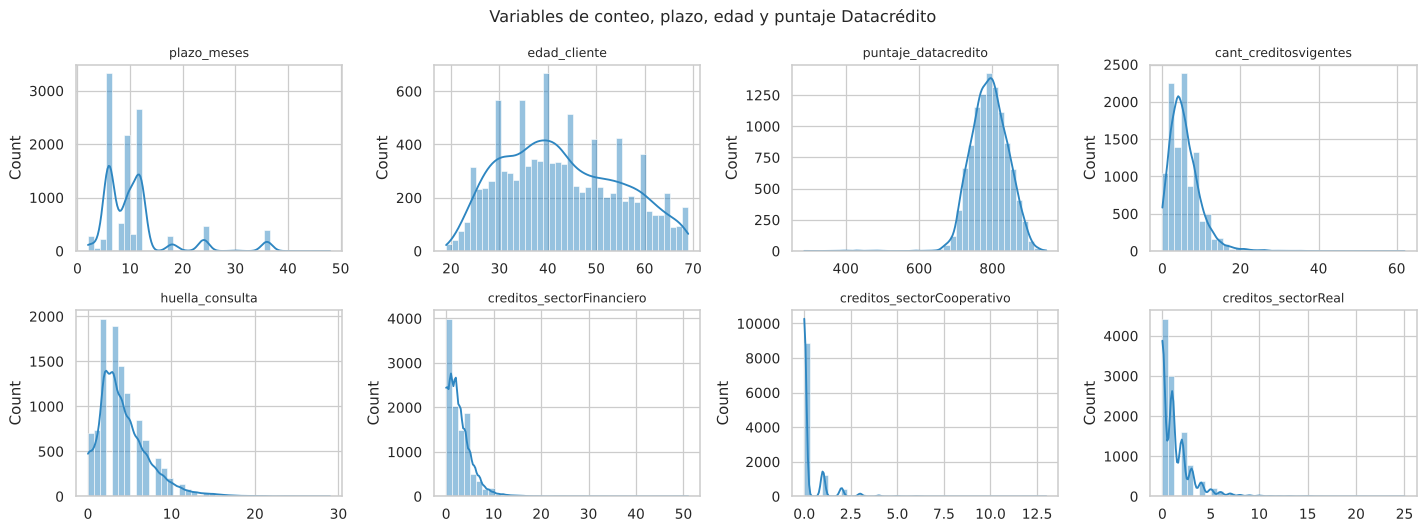

In [28]:
grilla_histogramas(df, CONTEOS, "Variables de conteo, plazo, edad y puntaje Datacrédito")

**Interpretación**
- `plazo_meses` toma pocos valores y se concentra en plazos típicos: 6, 10 y 12 meses reúnen el 70 % de los créditos.
- `edad_cliente` se reparte de forma amplia entre 19 y 69 años.
- `puntaje_datacredito` se concentra entre 750 y 830 con una cola a la izquierda (clientes de mayor riesgo).
- Las variables de conteo (`huella_consulta`, `cant_creditosvigentes`, créditos por sector) son discretas, con sesgo a la derecha: la mayoría tiene pocos créditos y pocas consultas, y unos pocos clientes tienen valores muy altos (hasta 62 créditos vigentes).

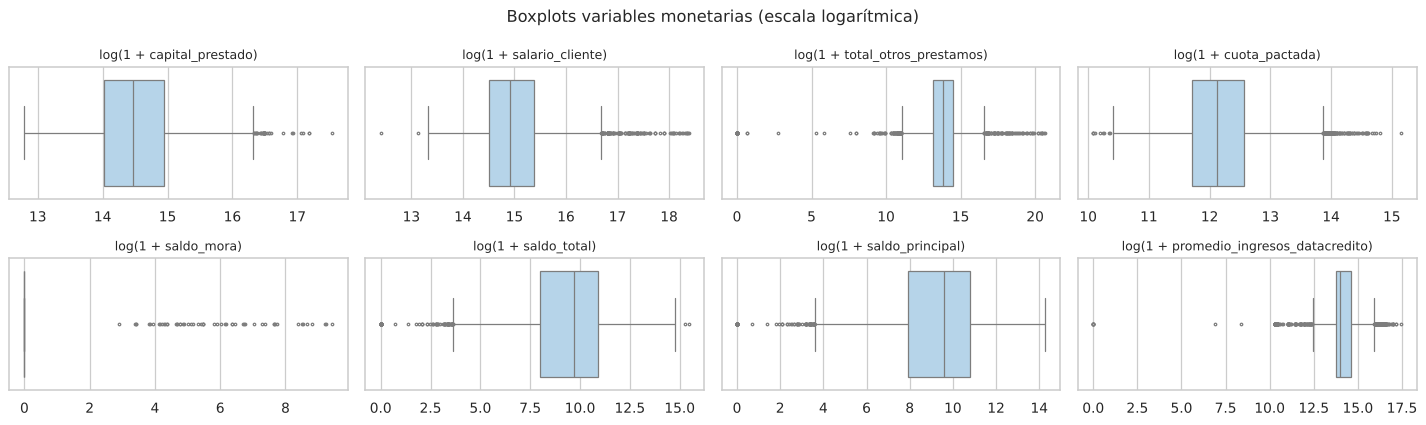

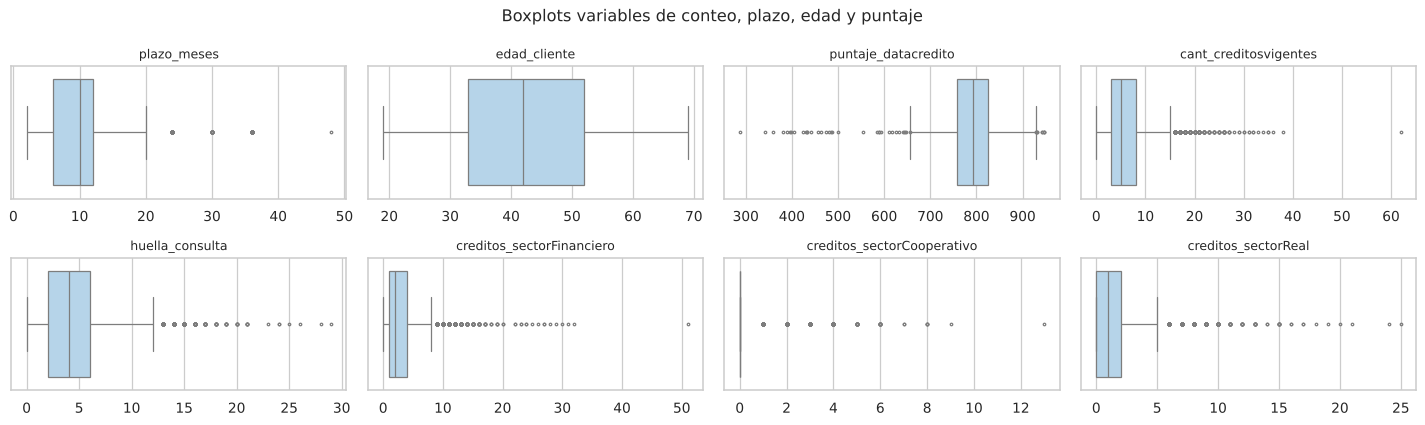

In [29]:
def grilla_boxplots(datos, columnas, titulo, log=False, n_col=4):
    n_filas = int(np.ceil(len(columnas) / n_col))
    fig, axes = plt.subplots(n_filas, n_col, figsize=(4 * n_col, 2.4 * n_filas))
    for ax, col in zip(axes.flat, columnas):
        serie = np.log1p(datos[col].dropna()) if log else datos[col].dropna()
        sns.boxplot(x=serie, color="#AED6F1", ax=ax, flierprops={"markersize": 2})
        ax.set_title(f"log(1 + {col})" if log else col, fontsize=10)
        ax.set_xlabel("")
    for ax in list(axes.flat)[len(columnas):]:
        ax.set_visible(False)
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()


grilla_boxplots(df, MONETARIAS, "Boxplots variables monetarias (escala logarítmica)", log=True)
grilla_boxplots(df, CONTEOS, "Boxplots variables de conteo, plazo, edad y puntaje")

**Interpretación.** Los boxplots muestran muchos puntos fuera de los bigotes en casi todas las variables. Sin embargo, la mayoría **no son errores**: son clientes con montos o cantidades de créditos altos pero posibles. Los errores evidentes (edades de 122 años, salarios de miles de millones, puntajes de 0) ya se convirtieron en nulos en la sección 2.4. Por eso **no se eliminan atípicos**; en su lugar se proponen transformaciones (logaritmo, escalado robusto) o modelos basados en árboles, que son poco sensibles a ellos.

#### Variables categóricas

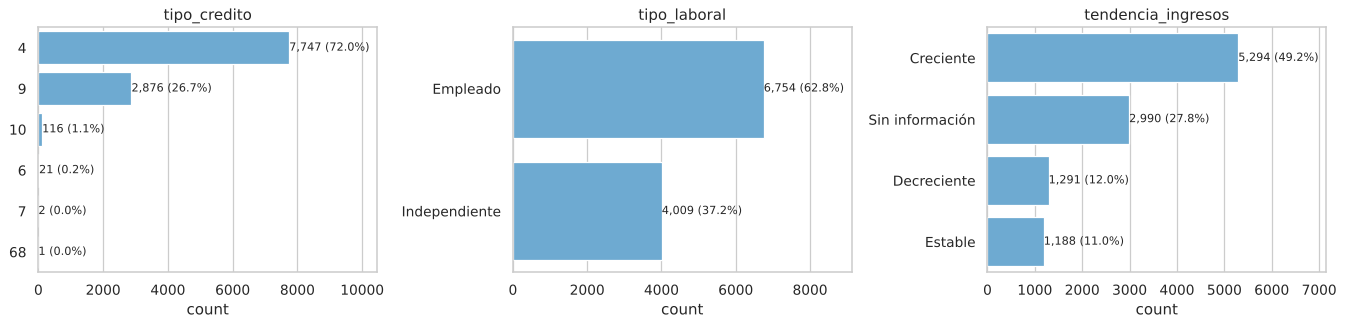

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, CATEGORICAS):
    serie = con_sin_informacion(df[col])
    orden = serie.value_counts().index
    sns.countplot(y=serie, order=orden, color="#5DADE2", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_width():,.0f} ({p.get_width() / len(df):.1%})",
                    (p.get_width(), p.get_y() + p.get_height() / 2), va="center", fontsize=9)
    ax.set_xlim(0, serie.value_counts().max() * 1.35)
plt.tight_layout()
plt.show()

In [31]:
for col in CATEGORICAS:
    vc = df[col].value_counts(dropna=False)
    display(pd.DataFrame({"registros": vc, "%": (vc / len(df) * 100).round(2)}).rename_axis(col))

,registros,%
tipo_credito,,
4,7747,71.98
9,2876,26.72
10,116,1.08
6,21,0.20
7,2,0.02
68,1,0.01


,registros,%
tipo_laboral,,
Empleado,6754,62.75
Independiente,4009,37.25


,registros,%
tendencia_ingresos,,
Creciente,5294,49.19
NaN,2990,27.78
Decreciente,1291,11.99
Estable,1188,11.04


**Interpretación**
- `tipo_credito`: dos líneas concentran el 98,7 % de los créditos (tipo 4 con 72 % y tipo 9 con 26,7 %). Los tipos 10 (116), 6 (21), 7 (2) y 68 (1) son **categorías raras**; al codificarlas con One-Hot generarían columnas casi vacías, así que se propone agrupar las de menos de 1 % en "Otros".
- `tipo_laboral`: 62,8 % empleados y 37,2 % independientes; está razonablemente balanceada.
- `tendencia_ingresos`: predomina "Creciente" (49,2 %), seguida de Decreciente (12 %) y Estable (11 %). El 27,8 % no tiene información; en lugar de imputar con la moda, se propone tratar "Sin información" como una categoría propia, porque coincide con los clientes sin datos de ingresos en Datacrédito.

#### Análisis temporal de la fecha de préstamo

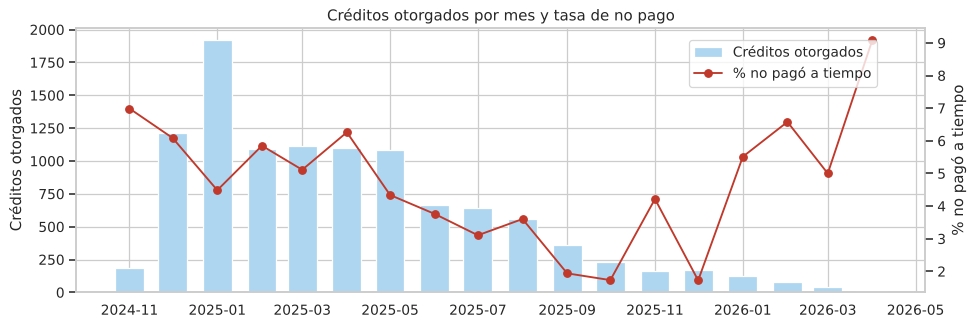

In [32]:
por_mes = df.set_index("fecha_prestamo").resample("MS")[OBJETIVO].agg(["count", "mean"])
por_mes["tasa_no_pago_%"] = (1 - por_mes["mean"]) * 100

fig, ax1 = plt.subplots(figsize=(11, 3.8))
ax1.bar(por_mes.index, por_mes["count"], width=20, color="#AED6F1", label="Créditos otorgados")
ax1.set_ylabel("Créditos otorgados")
ax2 = ax1.twinx()
ax2.plot(por_mes.index, por_mes["tasa_no_pago_%"], color=PALETA[0], marker="o", label="% no pagó a tiempo")
ax2.set_ylabel("% no pagó a tiempo")
ax2.grid(False)
ax1.set_title("Créditos otorgados por mes y tasa de no pago")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.show()

**Interpretación**
- El volumen de créditos es alto entre diciembre de 2024 y mayo de 2025 (más de 1.000 por mes, con pico de 1.917 en enero de 2025) y luego **cae de forma sostenida** hasta solo 11 créditos en abril de 2026.
- La tasa de no pago se mueve entre 2 % y 7 % y en los meses finales se vuelve inestable porque hay muy pocos créditos.
- **Precaución:** los créditos más recientes han tenido menos tiempo para caer en mora, lo que puede subestimar su tasa de no pago. Este cambio en la población a lo largo del tiempo es justamente lo que se medirá en la etapa de **monitoreo (data drift)**.

### 3.2 Análisis bivariable (relación con la variable objetivo)

#### Variables numéricas vs `Pago_atiempo`

Se comparan las distribuciones de cada variable entre los que pagaron y los que no. Como las variables no son normales, se usa la prueba no paramétrica **U de Mann-Whitney** (H0: las dos distribuciones son iguales). Un p-valor < 0,05 indica diferencia significativa.

In [33]:
def comparar_numericas(datos, columnas, objetivo=OBJETIVO):
    filas = []
    for col in columnas:
        no_paga = datos.loc[datos[objetivo] == 0, col].dropna()
        paga = datos.loc[datos[objetivo] == 1, col].dropna()
        p_valor = stats.mannwhitneyu(no_paga, paga).pvalue
        filas.append({
            "variable": col,
            "mediana_no_pago": no_paga.median(), "mediana_pago": paga.median(),
            "media_no_pago": no_paga.mean(), "media_pago": paga.mean(),
            "p_valor_mannwhitney": p_valor, "diferencia_significativa": p_valor < 0.05,
        })
    return pd.DataFrame(filas).set_index("variable").sort_values("p_valor_mannwhitney")


comparacion = comparar_numericas(df, NUMERICAS)
comparacion.style.format({"p_valor_mannwhitney": "{:.2e}"}, precision=1)

,mediana_no_pago,mediana_pago,media_no_pago,media_pago,p_valor_mannwhitney,diferencia_significativa
variable,,,,,,
saldo_mora,0.0,0.0,82.4,4.1,9.89e-29,True
puntaje_datacredito,769.0,792.0,763.9,792.9,7.91e-21,True
huella_consulta,5.0,4.0,5.2,4.2,3.91e-14,True
edad_cliente,37.0,42.0,40.0,43.0,1.00e-08,True
promedio_ingresos_datacredito,1052529.0,1211296.0,1605742.0,2023447.8,5.27e-06,True
capital_prestado,2268000.0,1908446.4,2781774.1,2416996.3,1.33e-05,True
creditos_sectorFinanciero,2.0,2.0,2.5,2.8,1.68e-03,True
total_otros_prestamos,900000.0,1000000.0,3903875.3,2728150.8,6.06e-03,True
creditos_sectorCooperativo,0.0,0.0,0.2,0.3,1.11e-02,True


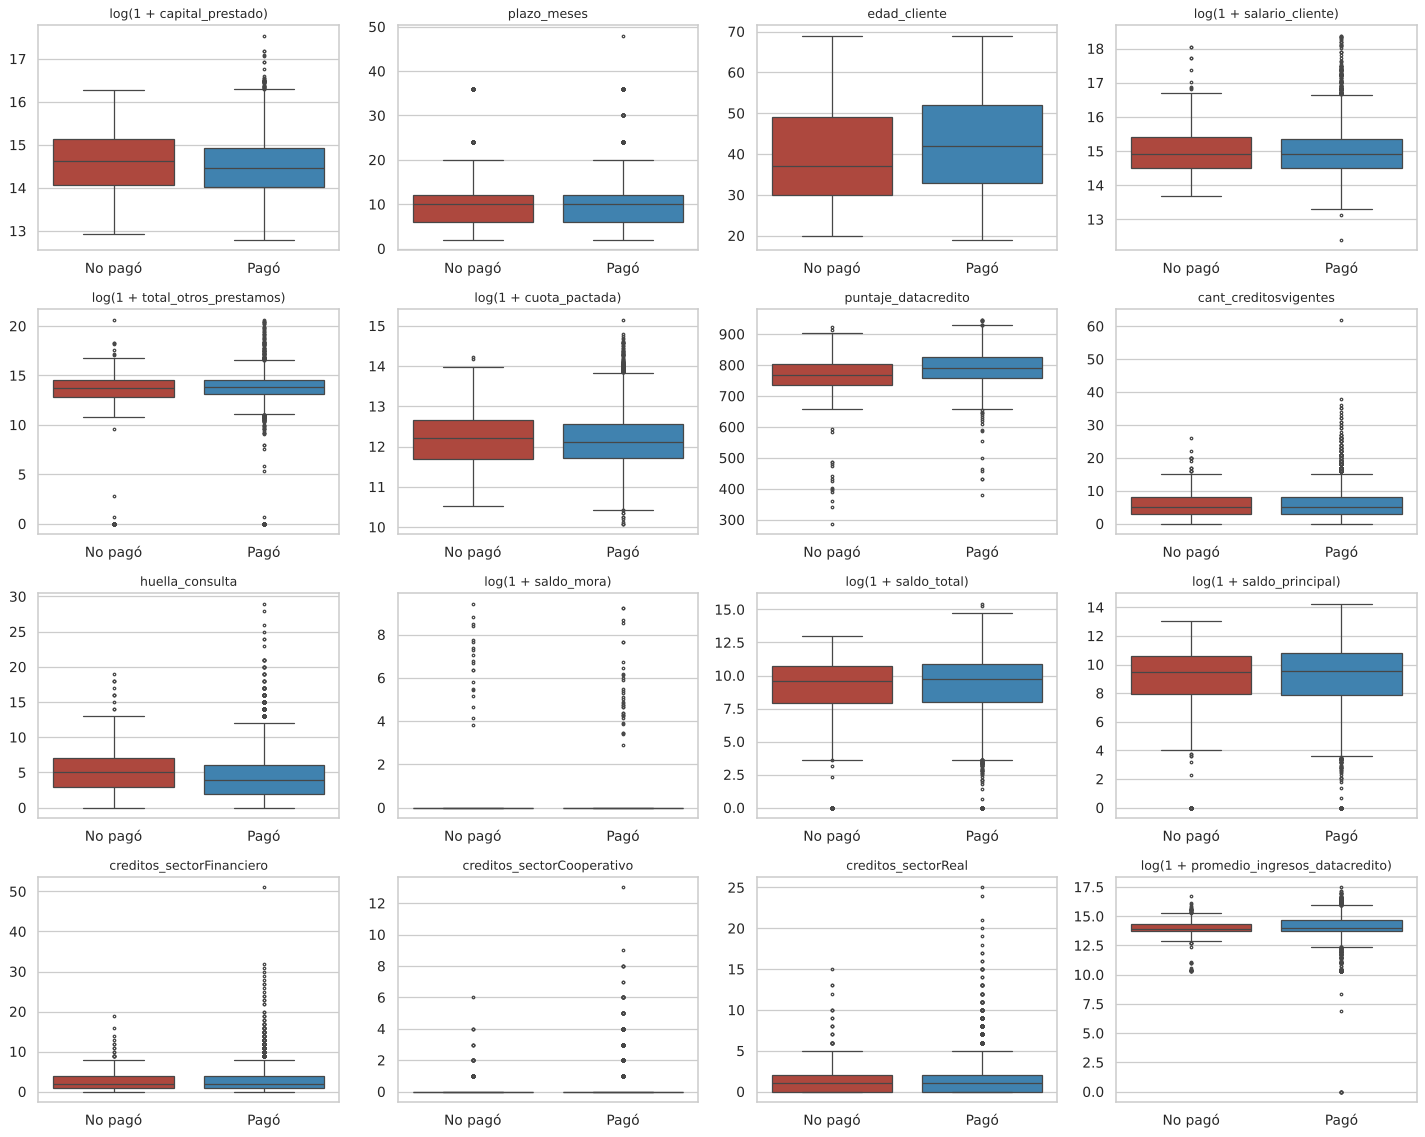

In [34]:
def boxplots_por_objetivo(datos, columnas, log_cols=(), n_col=4):
    n_filas = int(np.ceil(len(columnas) / n_col))
    fig, axes = plt.subplots(n_filas, n_col, figsize=(4 * n_col, 3.2 * n_filas))
    for ax, col in zip(axes.flat, columnas):
        y = np.log1p(datos[col]) if col in log_cols else datos[col]
        sns.boxplot(x=datos[OBJETIVO], y=y, hue=datos[OBJETIVO], palette=PALETA, legend=False,
                    ax=ax, flierprops={"markersize": 2})
        ax.set_title(f"log(1 + {col})" if col in log_cols else col, fontsize=10)
        ax.set_xticks([0, 1], ["No pagó", "Pagó"])
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in list(axes.flat)[len(columnas):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


boxplots_por_objetivo(df, NUMERICAS, log_cols=MONETARIAS)

**Interpretación.** Las variables con diferencia más clara entre quienes pagan y quienes no son:
- `saldo_mora`: los que no pagan tienen en promedio mucho más saldo en mora en la central (82 vs 4 pesos de media; la mediana es 0 en ambos grupos porque casi nadie tiene mora). Es la diferencia más significativa.
- `puntaje_datacredito`: mediana de **769 en los que no pagan frente a 792** en los que pagan. A menor puntaje, mayor riesgo, como se esperaría.
- `huella_consulta`: los que no pagan tienen **más consultas recientes** en la central (mediana 5 vs 4). Muchas consultas suelen indicar que el cliente está buscando crédito en varias entidades.
- `edad_cliente`: los que no pagan son **más jóvenes** (mediana 37 vs 42 años).
- `capital_prestado`: los que no pagan recibieron montos **más altos** (mediana 2,27 vs 1,91 millones).
- `promedio_ingresos_datacredito`: los que no pagan tienen **ingresos reportados menores** (mediana 1,05 vs 1,21 millones).
- **Sin diferencia significativa**: `salario_cliente` (el salario declarado por el cliente no discrimina, a diferencia del ingreso reportado por Datacrédito), `cuota_pactada`, `saldo_total`, `saldo_principal`, `cant_creditosvigentes`, `creditos_sectorReal` y `plazo_meses` (aunque el plazo sí muestra un patrón no lineal por grupos, como se ve en el siguiente gráfico).
- También resultan significativas, con diferencias pequeñas, `total_otros_prestamos`, `creditos_sectorFinanciero` y `creditos_sectorCooperativo`.

Las diferencias existen pero son **moderadas**: ninguna variable separa las clases por sí sola. Esto anticipa que el modelo tendrá que **combinar varias señales**.

Para ver mejor el efecto, se divide cada variable en **quintiles** (5 grupos con la misma cantidad de clientes) y se calcula la **tasa de no pago** en cada grupo. La línea punteada es la tasa general (4,75 %).

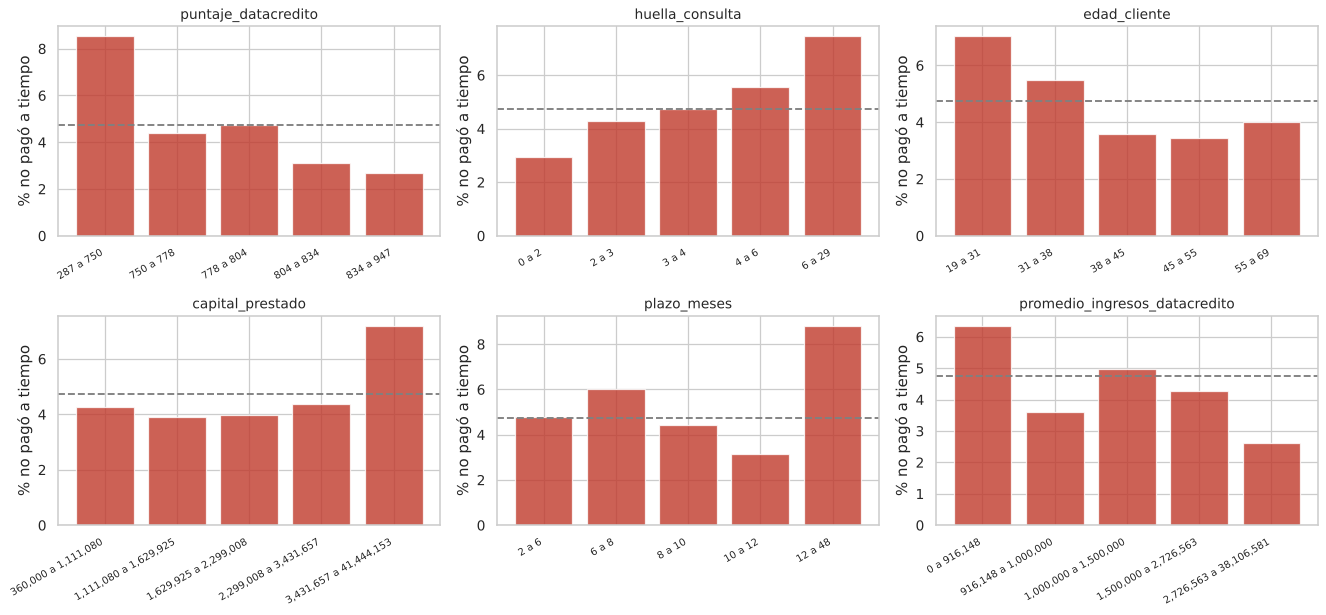

In [35]:
TASA_GENERAL = (1 - df[OBJETIVO].mean()) * 100


def tasa_no_pago_por_grupo(datos, columna, grupos=5):
    cortes = pd.qcut(datos[columna], grupos, duplicates="drop")
    tabla = datos.groupby(cortes, observed=True)[OBJETIVO].agg(["count", "mean"])
    tabla["tasa_no_pago_%"] = (1 - tabla["mean"]) * 100
    return tabla.drop(columns="mean")


VARIABLES_CLAVE = ["puntaje_datacredito", "huella_consulta", "edad_cliente",
                   "capital_prestado", "plazo_meses", "promedio_ingresos_datacredito"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, VARIABLES_CLAVE):
    tabla = tasa_no_pago_por_grupo(df, col)
    etiquetas = [f"{max(iv.left, 0):,.0f} a {iv.right:,.0f}" for iv in tabla.index]
    ax.bar(range(len(tabla)), tabla["tasa_no_pago_%"], color=PALETA[0], alpha=0.8)
    ax.axhline(TASA_GENERAL, ls="--", color="gray")
    ax.set_xticks(range(len(tabla)), etiquetas, rotation=30, ha="right", fontsize=8)
    ax.set_title(col, fontsize=11)
    ax.set_ylabel("% no pagó a tiempo")
plt.tight_layout()
plt.show()

**Interpretación** (tasa de no pago del quintil más riesgoso frente al menos riesgoso):
- **`puntaje_datacredito`**: 8,5 % en el quintil más bajo (≤ 750) frente a 2,7 % en el más alto: el riesgo es **3 veces mayor**. Es la relación más clara y monótona.
- **`huella_consulta`**: sube de forma constante, de 2,9 % (0 – 2 consultas) a 7,5 % (más de 6 consultas).
- **`edad_cliente`**: los menores de 31 años tienen 7,0 % de no pago, frente a 3,4 % – 4,0 % en los mayores de 38.
- **`capital_prestado`**: estable alrededor de 4 % en los primeros cuatro quintiles y sube a 7,2 % en los montos más altos (> 3,4 millones).
- **`plazo_meses`**: relación **no lineal**: los plazos de 11 – 12 meses tienen la menor tasa (3,2 %) y los plazos de más de 12 meses la mayor (8,8 %).
- **`promedio_ingresos_datacredito`**: los ingresos más bajos tienen más riesgo.

Las relaciones no lineales (plazo) y los efectos "de umbral" (capital) sugieren que **modelos basados en árboles** (Random Forest, Gradient Boosting) pueden aprovecharlas mejor que un modelo lineal.

#### Variables categóricas vs `Pago_atiempo`

Se usa la prueba **Chi-cuadrado de independencia** (H0: la categoría y el pago son independientes).

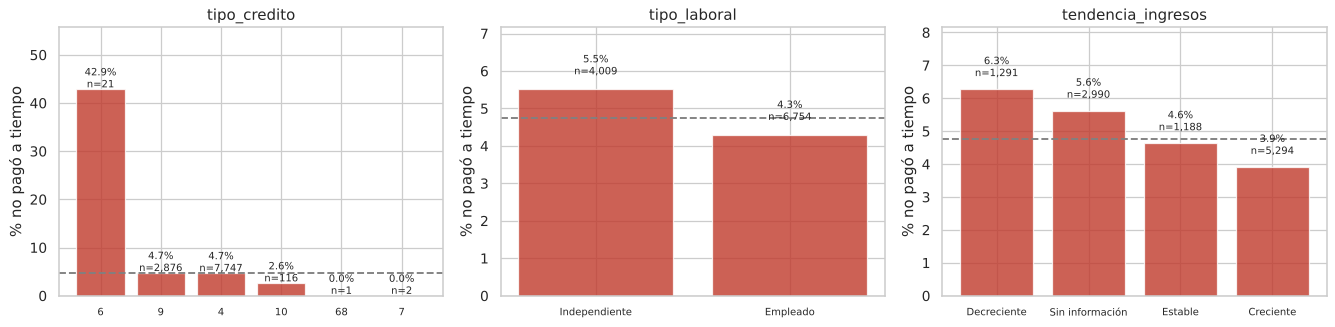

,chi2,grados_libertad,p_valor
variable,,,
tipo_credito,68.9,5,1.77e-13
tipo_laboral,8.0,1,4.69e-03
tendencia_ingresos,19.9,3,1.77e-04


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
resultados_chi2 = []
for ax, col in zip(axes, CATEGORICAS):
    serie = con_sin_informacion(df[col])
    tabla = df.groupby(serie, observed=True)[OBJETIVO].agg(["count", "mean"])
    tabla["tasa_no_pago_%"] = (1 - tabla["mean"]) * 100
    tabla = tabla.sort_values("tasa_no_pago_%", ascending=False)
    ax.bar(tabla.index.astype(str), tabla["tasa_no_pago_%"], color=PALETA[0], alpha=0.8)
    ax.axhline(TASA_GENERAL, ls="--", color="gray")
    for i, (tasa, n) in enumerate(zip(tabla["tasa_no_pago_%"], tabla["count"])):
        ax.text(i, tasa + 0.4, f"{tasa:.1f}%\nn={n:,}", ha="center", fontsize=8)
    ax.set_title(col)
    ax.set_ylabel("% no pagó a tiempo")
    ax.set_ylim(0, tabla["tasa_no_pago_%"].max() * 1.3)
    ax.tick_params(axis="x", labelsize=8)

    chi2, p, gl, _ = stats.chi2_contingency(pd.crosstab(serie, df[OBJETIVO]))
    resultados_chi2.append({"variable": col, "chi2": chi2, "grados_libertad": gl, "p_valor": p})
plt.tight_layout()
plt.show()

pd.DataFrame(resultados_chi2).set_index("variable").style.format({"p_valor": "{:.2e}", "chi2": "{:.1f}"})

In [37]:
for col in CATEGORICAS:
    serie = con_sin_informacion(df[col])
    display(pd.crosstab(serie, df[OBJETIVO].map(ETIQUETAS), normalize="index", margins=True)
            .mul(100).round(2).rename_axis(index=col, columns="% por fila"))

% por fila,No pagó a tiempo,Pagó a tiempo
tipo_credito,,
10,2.59,97.41
4,4.69,95.31
6,42.86,57.14
68,0.00,100.00
7,0.00,100.00
9,4.73,95.27
All,4.75,95.25


% por fila,No pagó a tiempo,Pagó a tiempo
tipo_laboral,,
Empleado,4.29,95.71
Independiente,5.51,94.49
All,4.75,95.25


% por fila,No pagó a tiempo,Pagó a tiempo
tendencia_ingresos,,
Creciente,3.91,96.09
Decreciente,6.27,93.73
Estable,4.63,95.37
Sin información,5.62,94.38
All,4.75,95.25


**Interpretación.** Las tres variables categóricas tienen relación **estadísticamente significativa** con el pago (p < 0,05):
- **`tipo_credito`**: el tipo 6 tiene 42,9 % de no pago (9 de 21 créditos), casi 9 veces la tasa general; los tipos 4 y 9 están en el promedio (4,7 %) y el 10 por debajo (2,6 %). El tipo 6 es una señal fuerte pero con muy pocos casos, así que hay que tratarlo con cuidado (si se agrupa con 7 y 68 en "Otros" debe evaluarse que no se pierda esa señal).
- **`tipo_laboral`**: los independientes tienen más riesgo (5,5 %) que los empleados (4,3 %), lo cual es coherente con ingresos menos estables.
- **`tendencia_ingresos`**: los ingresos **decrecientes** tienen la mayor tasa (6,3 %), luego "Sin información" (5,6 %), Estable (4,6 %) y Creciente la menor (3,9 %). El orden confirma que tratarla como **ordinal** tiene sentido, y que "Sin información" se comporta distinto y conviene mantenerla como categoría aparte.

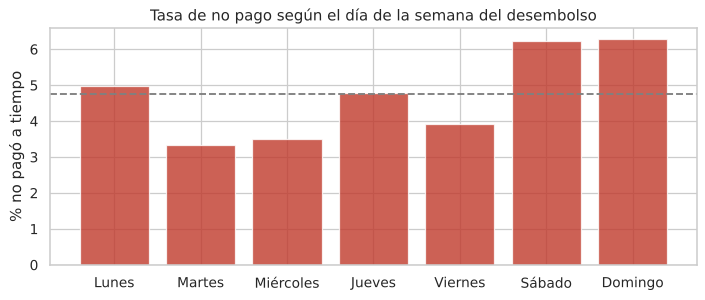

,count,tasa_no_pago_%
Lunes,1307,4.97
Martes,1412,3.33
Miércoles,1254,3.51
Jueves,1899,4.79
Viernes,1789,3.91
Sábado,1621,6.23
Domingo,1481,6.28


In [38]:
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
tabla_dia = df.groupby(df["fecha_prestamo"].dt.dayofweek)[OBJETIVO].agg(["count", "mean"])
tabla_dia["tasa_no_pago_%"] = (1 - tabla_dia["mean"]) * 100
tabla_dia.index = dias

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(tabla_dia.index, tabla_dia["tasa_no_pago_%"], color=PALETA[0], alpha=0.8)
ax.axhline(TASA_GENERAL, ls="--", color="gray")
ax.set_title("Tasa de no pago según el día de la semana del desembolso")
ax.set_ylabel("% no pagó a tiempo")
plt.tight_layout()
plt.show()
tabla_dia.drop(columns="mean")

**Interpretación.** Los créditos desembolsados en **fin de semana** (sábado 6,2 %, domingo 6,3 %) tienen más no pago que los de martes y miércoles (3,3 % – 3,5 %). Puede reflejar un canal de venta distinto en fin de semana. El **día de la semana** es entonces un atributo derivado de la fecha que vale la pena probar.

### 3.3 Análisis multivariable

#### Matriz de correlación

Se usa la correlación de **Spearman** (basada en rangos), más adecuada que Pearson porque las variables son asimétricas y tienen valores atípicos.

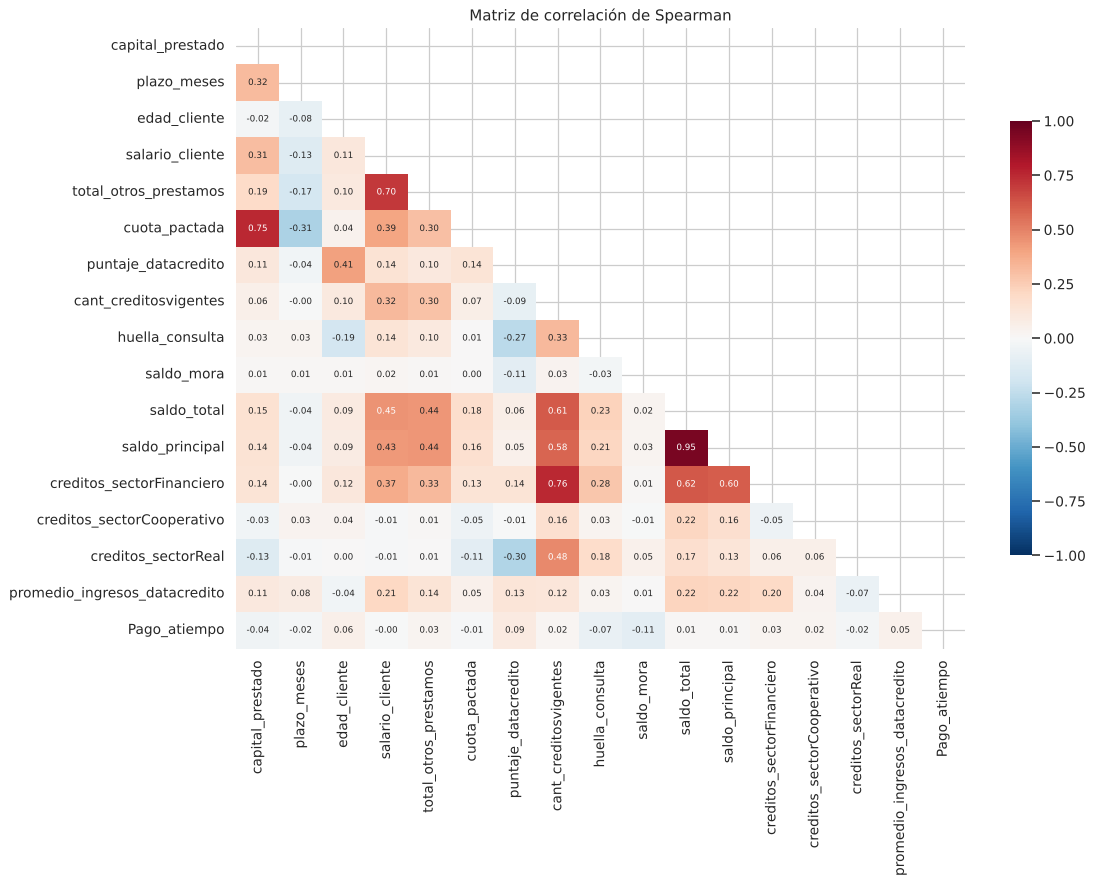

In [39]:
corr = df[NUMERICAS + [OBJETIVO]].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()

In [40]:
pares = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
         .rename("spearman").to_frame())
pares["abs"] = pares["spearman"].abs()
print("Pares de variables con mayor correlación:")
display(pares.sort_values("abs", ascending=False).head(8).drop(columns="abs"))

print(f"Correlación con {OBJETIVO}:")
display(corr[OBJETIVO].drop(OBJETIVO).sort_values().to_frame("spearman"))

Pares de variables con mayor correlación:


,,spearman
saldo_total,saldo_principal,0.95
cant_creditosvigentes,creditos_sectorFinanciero,0.76
capital_prestado,cuota_pactada,0.75
salario_cliente,total_otros_prestamos,0.70
saldo_total,creditos_sectorFinanciero,0.62
cant_creditosvigentes,saldo_total,0.61
saldo_principal,creditos_sectorFinanciero,0.60
cant_creditosvigentes,saldo_principal,0.58


Correlación con Pago_atiempo:


,spearman
saldo_mora,-0.11
huella_consulta,-0.07
capital_prestado,-0.04
creditos_sectorReal,-0.02
plazo_meses,-0.02
cuota_pactada,-0.01
salario_cliente,-0.00
saldo_principal,0.01
saldo_total,0.01
cant_creditosvigentes,0.02


**Interpretación**
- **Multicolinealidad**: `saldo_total` y `saldo_principal` tienen correlación de **0,95**, es decir, miden casi lo mismo; también `cant_creditosvigentes` con `creditos_sectorFinanciero` (0,76), `capital_prestado` con `cuota_pactada` (0,75) y `salario_cliente` con `total_otros_prestamos` (0,70). Para modelos lineales conviene conservar solo una de cada par muy correlacionado (por ejemplo, eliminar `saldo_principal`); los modelos de árboles lo toleran mejor.
- **Relación con la objetivo**: todas las correlaciones individuales son **débiles** (|r| < 0,11). Las más fuertes son `saldo_mora` (-0,11), `puntaje_datacredito` (+0,09), `huella_consulta` (-0,07), `edad_cliente` (+0,06) y `promedio_ingresos_datacredito` (+0,05), en línea con el análisis bivariable.
- Que las correlaciones lineales sean bajas **no** significa que no haya información: en la sección anterior se vieron relaciones no lineales y por grupos que la correlación no captura.

#### Pairplot de las variables más relevantes

Para que el gráfico sea legible se usa una muestra estratificada (todos los que no pagaron + una muestra de los que sí) y escala logarítmica en los montos.

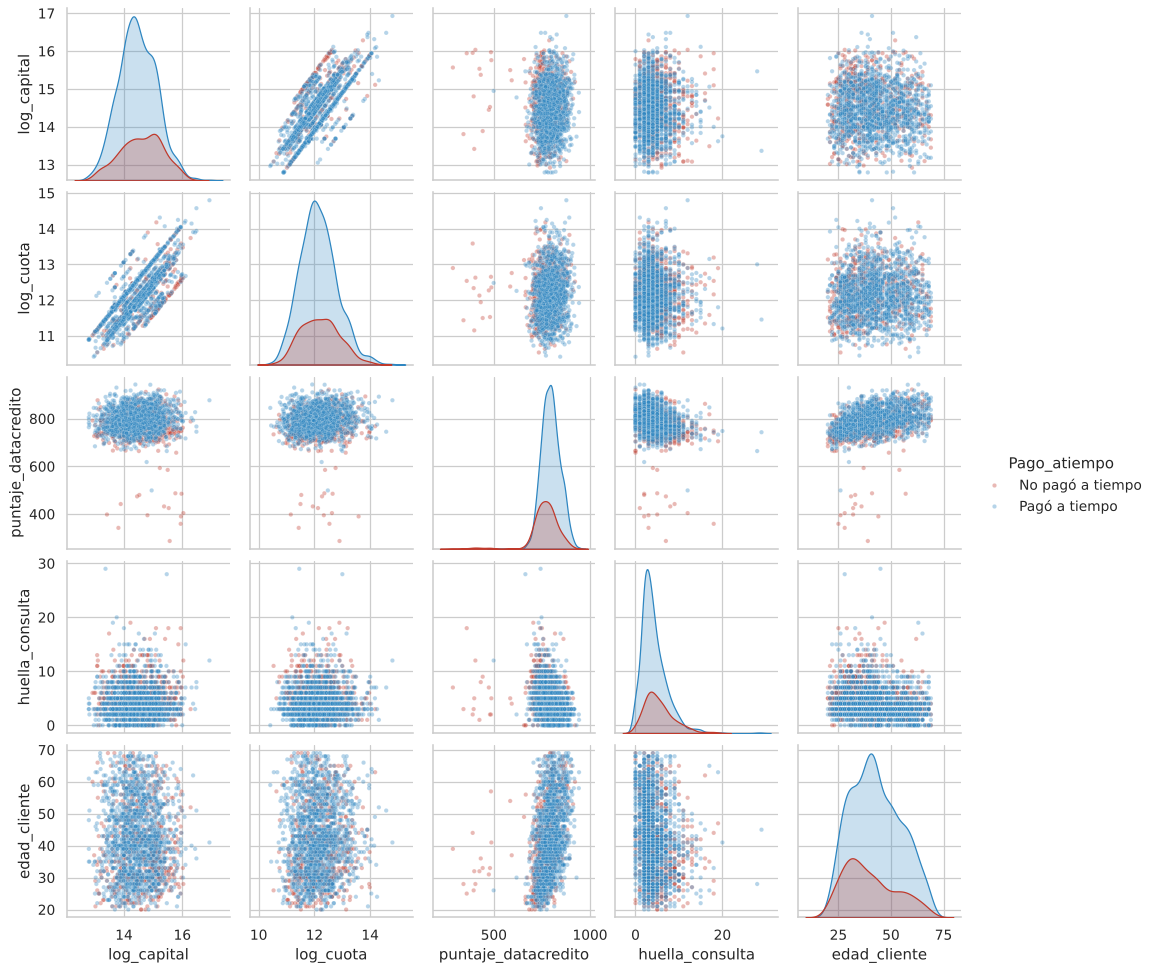

In [41]:
muestra = pd.concat([
    df[df[OBJETIVO] == 0],
    df[df[OBJETIVO] == 1].sample(1500, random_state=42),
])
vars_pair = pd.DataFrame({
    "log_capital": np.log1p(muestra["capital_prestado"]),
    "log_cuota": np.log1p(muestra["cuota_pactada"]),
    "puntaje_datacredito": muestra["puntaje_datacredito"],
    "huella_consulta": muestra["huella_consulta"],
    "edad_cliente": muestra["edad_cliente"],
    OBJETIVO: muestra[OBJETIVO].map(ETIQUETAS),
})
sns.pairplot(vars_pair.dropna(), hue=OBJETIVO,
             palette={ETIQUETAS[0]: PALETA[0], ETIQUETAS[1]: PALETA[1]},
             plot_kws={"alpha": 0.35, "s": 12}, diag_kind="kde", height=2.2)
plt.show()

**Interpretación**
- En las diagonales (KDE), las curvas de los que no pagan (rojo) están corridas hacia **menor puntaje Datacrédito, más huella de consulta, menor edad y mayor capital**, lo que confirma lo visto en el análisis bivariable.
- En los diagramas de dispersión **no se ven zonas claramente separadas**: las dos clases se superponen mucho. Esto indica que el problema no es trivial y que un modelo tendrá que combinar varias variables a la vez.
- `log_capital` y `log_cuota` forman una relación casi lineal (muy correlacionadas), con "bandas" que corresponden a los distintos plazos.

#### Tablas cruzadas entre variables categóricas

In [42]:
print("Número de créditos por tipo laboral y tipo de crédito")
display(pd.crosstab(df["tipo_laboral"], df["tipo_credito"], margins=True))

print("Tasa de no pago (%) por tipo laboral y tipo de crédito")
display(df.pivot_table(index="tipo_laboral", columns="tipo_credito", values=OBJETIVO,
                       aggfunc=lambda s: (1 - s.mean()) * 100, observed=True).round(2))

print("Tasa de no pago (%) por tipo laboral y tendencia de ingresos")
display(df.assign(tendencia=con_sin_informacion(df["tendencia_ingresos"]))
          .pivot_table(index="tipo_laboral", columns="tendencia", values=OBJETIVO,
                       aggfunc=lambda s: (1 - s.mean()) * 100, observed=True).round(2))

Número de créditos por tipo laboral y tipo de crédito


tipo_credito,10,4,6,68,7,9,All
tipo_laboral,,,,,,,
Empleado,75,5052,21,1,1,1604,6754
Independiente,41,2695,0,0,1,1272,4009
All,116,7747,21,1,2,2876,10763


Tasa de no pago (%) por tipo laboral y tipo de crédito


tipo_credito,10,4,6,68,7,9
tipo_laboral,,,,,,
Empleado,2.67,4.14,42.86,0.00,0.00,4.36
Independiente,2.44,5.71,NaN,NaN,0.00,5.19


Tasa de no pago (%) por tipo laboral y tendencia de ingresos


tendencia,Creciente,Decreciente,Estable,Sin información
tipo_laboral,,,,
Empleado,3.56,5.87,4.49,5.20
Independiente,4.82,7.34,4.80,5.96


**Interpretación**
- Los créditos tipo 6 son **solo para empleados** (21 de 21): su alta tasa de no pago no está asociada a independientes.
- En las dos líneas principales (4 y 9) los independientes tienen más riesgo que los empleados (5,7 % vs 4,1 % en el tipo 4; 5,2 % vs 4,4 % en el tipo 9): el efecto del tipo laboral se mantiene dentro de cada línea de crédito.
- La combinación de **independiente con ingresos decrecientes** es la de mayor riesgo, lo que sugiere posibles interacciones entre variables que un modelo de árboles puede capturar.

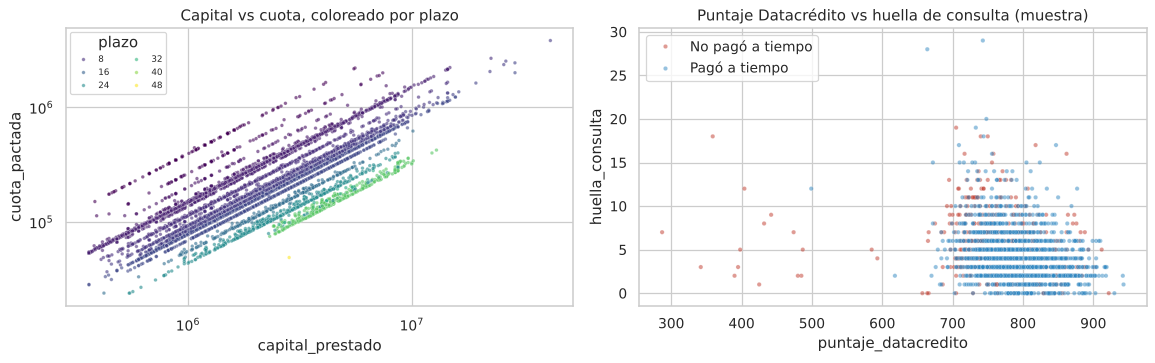

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.scatterplot(data=df, x="capital_prestado", y="cuota_pactada", hue="plazo_meses",
                palette="viridis", s=8, alpha=0.6, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Capital vs cuota, coloreado por plazo")
axes[0].legend(title="plazo", fontsize=7, ncol=2, loc="upper left")

sns.scatterplot(data=muestra, x="puntaje_datacredito", y="huella_consulta", hue=muestra[OBJETIVO].map(ETIQUETAS),
                palette={ETIQUETAS[0]: PALETA[0], ETIQUETAS[1]: PALETA[1]}, s=12, alpha=0.5, ax=axes[1])
axes[1].set_title("Puntaje Datacrédito vs huella de consulta (muestra)")
axes[1].legend(title="")
plt.tight_layout()
plt.show()

**Interpretación**
- **Capital vs cuota**: la relación está totalmente determinada por el plazo (a mayor plazo, menor cuota para el mismo capital). Las tres variables son redundantes entre sí; la información "nueva" estaría en cómo se relaciona la cuota con la **capacidad de pago** del cliente (ver atributos derivados).
- **Puntaje vs huella**: los puntos rojos (no pagó) se concentran más en la zona de **puntaje bajo y muchas consultas**, aunque se mezclan con los azules. La combinación de ambas variables es más informativa que cada una por separado.

## 4. Atributos derivados

A partir del conocimiento del negocio se proponen nuevas variables calculadas. Se crean aquí de forma exploratoria para evaluar si aportan señal; su construcción definitiva irá en `ft_engineering.py` (Fase 2).

| Atributo | Fórmula | Idea de negocio |
|---|---|---|
| `ratio_cuota_salario` | cuota / salario | Qué parte del ingreso se va en la cuota (capacidad de pago) |
| `ratio_capital_salario` | capital / salario | Tamaño del crédito frente al ingreso |
| `ratio_endeudamiento` | otros préstamos / salario | Nivel de endeudamiento declarado |
| `tiene_mora` | saldo_mora > 0 | Tiene obligaciones en mora en la central |
| `sin_info_ingresos_dc` | promedio_ingresos_datacredito es nulo | Datacrédito no tiene información de sus ingresos |
| `total_creditos_sectores` | suma de créditos por sector | Exposición total por sector |
| `mes_prestamo`, `dia_semana` | de `fecha_prestamo` | Estacionalidad y canal |

In [44]:
derivadas = pd.DataFrame(index=df.index)
derivadas["ratio_cuota_salario"] = df["cuota_pactada"] / df["salario_cliente"]
derivadas["ratio_capital_salario"] = df["capital_prestado"] / df["salario_cliente"]
derivadas["ratio_endeudamiento"] = df["total_otros_prestamos"] / df["salario_cliente"]
derivadas["tiene_mora"] = (df["saldo_mora"] > 0).astype(int)
derivadas["sin_info_ingresos_dc"] = df["promedio_ingresos_datacredito"].isna().astype(int)
derivadas["total_creditos_sectores"] = df[["creditos_sectorFinanciero", "creditos_sectorCooperativo",
                                           "creditos_sectorReal"]].sum(axis=1)
derivadas["mes_prestamo"] = df["fecha_prestamo"].dt.month
derivadas["dia_semana"] = df["fecha_prestamo"].dt.dayofweek
derivadas[OBJETIVO] = df[OBJETIVO]

derivadas.describe().T

,count,mean,std,min,25%,50%,75%,max
ratio_cuota_salario,"10,658.00",0.08,0.07,0.00,0.04,0.06,0.10,1.30
ratio_capital_salario,"10,658.00",0.81,0.66,0.02,0.37,0.64,1.02,8.69
ratio_endeudamiento,"10,657.00",0.39,0.97,0.00,0.21,0.33,0.47,83.33
tiene_mora,"10,763.00",0.01,0.07,0.00,0.00,0.00,0.00,1.00
sin_info_ingresos_dc,"10,763.00",0.27,0.45,0.00,0.00,0.00,1.00,1.00
total_creditos_sectores,"10,763.00",4.35,3.49,0.00,2.00,4.00,6.00,60.00
mes_prestamo,"10,763.00",5.27,3.72,1.00,2.00,4.00,8.00,12.00
dia_semana,"10,763.00",3.14,1.93,0.00,1.00,3.00,5.00,6.00
Pago_atiempo,"10,763.00",0.95,0.21,0.00,1.00,1.00,1.00,1.00


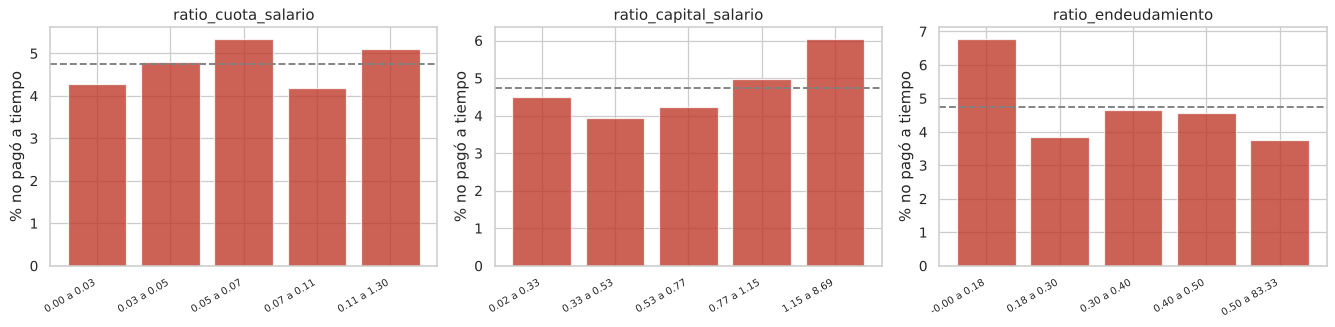

,count,tasa_no_pago_%
tiene_mora,,
0,10708,4.59
1,55,36.36


,count,tasa_no_pago_%
sin_info_ingresos_dc,,
0,7833,4.38
1,2930,5.73


In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["ratio_cuota_salario", "ratio_capital_salario", "ratio_endeudamiento"]):
    tabla = tasa_no_pago_por_grupo(derivadas, col)
    etiquetas = [f"{iv.left:.2f} a {iv.right:.2f}" for iv in tabla.index]
    ax.bar(range(len(tabla)), tabla["tasa_no_pago_%"], color=PALETA[0], alpha=0.8)
    ax.axhline(TASA_GENERAL, ls="--", color="gray")
    ax.set_xticks(range(len(tabla)), etiquetas, rotation=30, ha="right", fontsize=8)
    ax.set_title(col)
    ax.set_ylabel("% no pagó a tiempo")
plt.tight_layout()
plt.show()

for col in ["tiene_mora", "sin_info_ingresos_dc"]:
    t = derivadas.groupby(col)[OBJETIVO].agg(["count", "mean"])
    t["tasa_no_pago_%"] = ((1 - t["mean"]) * 100).round(2)
    display(t.drop(columns="mean").rename_axis(col))

**Interpretación**
- **`tiene_mora` es la señal más fuerte de toda la base**: los 55 clientes con saldo en mora en la central tienen **36,4 %** de no pago, frente a 4,6 % del resto (casi 8 veces más).
- **`sin_info_ingresos_dc`**: los clientes sin información de ingresos en Datacrédito tienen 5,7 % de no pago frente a 4,4 %: el nulo es informativo, por eso conviene crear la bandera además de imputar.
- **`ratio_capital_salario`**: el riesgo sube cuando el crédito supera 1,15 veces el salario (6,1 % en el último quintil).
- **`ratio_endeudamiento`**: resultado **contraintuitivo**: el quintil con menor endeudamiento declarado es el de mayor riesgo (6,8 %). Una posible explicación es que los clientes sin otros créditos tienen poco historial (perfil "nuevo" o de menor acceso al sistema financiero). Es una hipótesis que el modelo podrá confirmar o descartar.
- **`ratio_cuota_salario`**: no muestra un patrón claro (entre 4,2 % y 5,3 %). Como el salario declarado no discrimina por sí solo, se probará en el modelo pero sin esperar mucho de esta variable.
- `dia_semana` (ver 3.2) también aporta señal (fin de semana con más riesgo).

## 5. Reglas de validación de datos

Con base en el análisis se definen reglas que **todo dato nuevo** debe cumplir antes de entrar al modelo. Estas reglas se usarán en etapas posteriores del proyecto (pipeline de features, despliegue y monitoreo).

| # | Variable | Regla | Acción si no se cumple |
|---|---|---|---|
| 1 | Todas | Deben existir las 23 columnas del esquema | Rechazar la carga |
| 2 | `Pago_atiempo` | Solo valores 0 o 1, sin nulos | Rechazar el registro |
| 3 | `tipo_credito` | Código en el catálogo conocido {4, 6, 7, 9, 10, 68} | Asignar a "Otros" y alertar |
| 4 | `tipo_laboral` | Valor en {Empleado, Independiente} | → nulo |
| 5 | `tendencia_ingresos` | Valor en {Decreciente, Estable, Creciente} o nulo | → nulo |
| 6 | `edad_cliente` | Entre 18 y 100 años | → nulo |
| 7 | `salario_cliente` | Entre 100.000 y 100.000.000 | → nulo |
| 8 | `total_otros_prestamos` | Entre 0 y 1.000.000.000 | → nulo |
| 9 | `puntaje_datacredito` | Entre 150 y 950 | → nulo |
| 10 | `plazo_meses` | Entre 1 y 60 | → nulo |
| 11 | `capital_prestado`, `cuota_pactada` | Mayores que 0 y sin nulos | Rechazar el registro |
| 12 | Saldos, conteos e ingresos | Mayores o iguales a 0 | → nulo |
| 13 | `fecha_prestamo` | Fecha válida y no futura | Rechazar el registro |
| 14 | `cuota_pactada` | Menor o igual que `capital_prestado` | Alertar para revisión |

In [46]:
def validar_datos(datos):
    # Evalúa las reglas de validación y retorna cuántos registros incumplen cada una.
    no_negativas = ["saldo_mora", "saldo_total", "saldo_principal", "cant_creditosvigentes",
                    "huella_consulta", "creditos_sectorFinanciero", "creditos_sectorCooperativo",
                    "creditos_sectorReal", "promedio_ingresos_datacredito"]
    reglas = {
        "R2 objetivo en {0,1}": ~datos[OBJETIVO].isin([0, 1]),
        "R3 tipo_credito en catálogo": ~datos["tipo_credito"].astype(str).isin(["4", "6", "7", "9", "10", "68"]),
        "R4 tipo_laboral válido": ~datos["tipo_laboral"].isin(["Empleado", "Independiente"]),
        "R5 tendencia_ingresos válida": datos["tendencia_ingresos"].notna()
                                         & ~datos["tendencia_ingresos"].isin(CATEGORIAS_TENDENCIA),
        "R6 edad entre 18 y 100": ~datos["edad_cliente"].between(18, 100) & datos["edad_cliente"].notna(),
        "R7 salario entre 100 mil y 100 millones": ~datos["salario_cliente"].between(1e5, 1e8)
                                                   & datos["salario_cliente"].notna(),
        "R8 otros préstamos <= 1.000 millones": ~datos["total_otros_prestamos"].between(0, 1e9)
                                                & datos["total_otros_prestamos"].notna(),
        "R9 puntaje Datacrédito 150-950": ~datos["puntaje_datacredito"].between(150, 950)
                                          & datos["puntaje_datacredito"].notna(),
        "R10 plazo entre 1 y 60": ~datos["plazo_meses"].between(1, 60) & datos["plazo_meses"].notna(),
        "R11 capital y cuota > 0": (datos["capital_prestado"].fillna(0) <= 0) | (datos["cuota_pactada"].fillna(0) <= 0),
        "R12 saldos y conteos >= 0": (datos[no_negativas] < 0).any(axis=1),
        "R13 fecha válida y no futura": datos["fecha_prestamo"].isna() | (datos["fecha_prestamo"] > pd.Timestamp.now()),
        "R14 cuota <= capital": datos["cuota_pactada"] > datos["capital_prestado"],
    }
    reporte = pd.DataFrame({"registros_que_incumplen": {r: int(m.sum()) for r, m in reglas.items()}})
    reporte["%"] = (reporte["registros_que_incumplen"] / len(datos) * 100).round(2)
    return reporte


print("Validación sobre la base CRUDA (original):")
display(validar_datos(df_crudo))
print("Validación sobre la base LIMPIA:")
display(validar_datos(df))

Validación sobre la base CRUDA (original):


,registros_que_incumplen,%
"R2 objetivo en {0,1}",0,0.00
R3 tipo_credito en catálogo,0,0.00
R4 tipo_laboral válido,0,0.00
R5 tendencia_ingresos válida,58,0.54
R6 edad entre 18 y 100,150,1.39
R7 salario entre 100 mil y 100 millones,105,0.98
R8 otros préstamos <= 1.000 millones,13,0.12
R9 puntaje Datacrédito 150-950,153,1.42
R10 plazo entre 1 y 60,1,0.01
R11 capital y cuota > 0,0,0.00


Validación sobre la base LIMPIA:


,registros_que_incumplen,%
"R2 objetivo en {0,1}",0,0.00
R3 tipo_credito en catálogo,0,0.00
R4 tipo_laboral válido,0,0.00
R5 tendencia_ingresos válida,0,0.00
R6 edad entre 18 y 100,0,0.00
R7 salario entre 100 mil y 100 millones,0,0.00
R8 otros préstamos <= 1.000 millones,0,0.00
R9 puntaje Datacrédito 150-950,0,0.00
R10 plazo entre 1 y 60,0,0.00
R11 capital y cuota > 0,0,0.00


**Interpretación.** Sobre la base original, las reglas detectan exactamente los problemas encontrados en la sección 2.4 (150 edades, 105 salarios, 159 – 6 = 153 puntajes Datacrédito, 58 tendencias, 13 otros préstamos, 1 plazo). Después de la limpieza, **ninguna regla se incumple**. La función `validar_datos` podrá reutilizarse en el despliegue y en el monitoreo para revisar los datos nuevos antes de predecir.

## 6. Transformaciones propuestas para la Fase 2

| Variable(s) | Transformación | Motivo |
|---|---|---|
| `puntaje`, `saldo_mora_codeudor` | Eliminar | Fuga de información / casi constante |
| Valores imposibles (sección 2.4) | → `NaN` con las reglas de validación | Unificar nulos |
| Numéricas | `SimpleImputer(strategy="median")` | La mediana es robusta a atípicos y asimetría |
| Monetarias | `log1p` + escalado (`StandardScaler` o `RobustScaler`) para modelos lineales | Asimetría fuerte y atípicos |
| `tipo_credito` | Agrupar categorías con < 1 % en "Otros" + `OneHotEncoder(handle_unknown="ignore")` | Categorías raras; nominal |
| `tipo_laboral` | `OneHotEncoder` (o binaria 0/1) | Nominal dicotómica |
| `tendencia_ingresos` | Imputar "Sin información" + `OrdinalEncoder` con orden Decreciente < Estable < Creciente | Ordinal; el nulo tiene significado propio |
| `saldo_mora` | Bandera `tiene_mora` | Concentrada en cero; la presencia de mora es lo que importa |
| `saldo_principal` | Evaluar eliminación | Correlación 0,95 con `saldo_total` |
| `fecha_prestamo` | Derivar `dia_semana` y `mes_prestamo`; no usar la fecha directa | Una fecha exacta no generaliza |
| Derivadas | `tiene_mora`, `sin_info_ingresos_dc`, `ratio_capital_salario`, `ratio_endeudamiento`, `ratio_cuota_salario` | Señal adicional (sección 4) |
| Partición | `train_test_split(stratify=y)` | Desbalance 95/5 |

Esto corresponde al `ColumnTransformer` que pide el enunciado: una rama **numérica** (`SimpleImputer`), una **categórica** (`SimpleImputer` + `OneHotEncoder`) y una **categórica ordinal** (`SimpleImputer` + `OrdinalEncoder`).

## 7. Conclusiones

1. **Calidad de datos**: la base es de buen tamaño (10.763 créditos) y sin duplicados, pero tenía **nulos disfrazados** que se unificaron como `NaN`: edades de 122 años, salarios en 0 o de miles de millones, puntajes Datacrédito en 0 y números dentro de `tendencia_ingresos`.
2. **Fuga de información**: `puntaje` separaba casi perfectamente la variable objetivo (99,8 % de aciertos con una sola regla). Se eliminó porque no estaría disponible de esa forma al momento de aprobar un crédito. Detectar esto evita entregar un modelo que se ve perfecto y falla en producción.
3. **Desbalance**: solo el 4,75 % no paga a tiempo; la evaluación del modelo debe centrarse en la detección de esa clase (recall, F1, PR-AUC), con partición estratificada.
4. **Variables con más señal**: tener saldo en mora (36,4 % de no pago), puntaje Datacrédito bajo, muchas consultas recientes (huella), clientes jóvenes, montos altos, plazos mayores a 12 meses, ingresos decrecientes, independientes, crédito tipo 6 y desembolsos en fin de semana.
5. **Relaciones débiles y no lineales**: ninguna variable separa las clases por sí sola y varias relaciones son no lineales, por lo que se espera que **modelos de árboles y ensambles** (Random Forest, Gradient Boosting/XGBoost) superen a la regresión logística. Aun así, la regresión logística se entrenará como línea base.
6. **Para la Fase 2** quedan definidas las reglas de validación, las transformaciones y los atributos derivados que se implementarán en `ft_engineering.py`.